# 2. Complex vectors

You know vectors from ML: a list of numbers such as an embedding. In a quantum computer the list holds **complex numbers**, and that list is the state of a qubit. This folder builds the idea in five steps, one notebook each, and every step is a prerequisite for the next:

| # | Notebook | What you learn | Why quantum computing needs it |
|---|---|---|---|
| 1 | `1_complex_numbers` | real part, imaginary part, what `i` does, addition and subtraction, magnitude, phase, conjugate, polar form, Euler's formula, multiplication as rotation | an amplitude has a size (→ probability) and a phase (→ interference) |
| **2** | **`2_complex_vectors`** (you are here) | lists of complex numbers, adding and scaling them, global and relative phase, conjugate, inner product, norm and normalization of a vector | a qubit state is a vector `(α, β)` |
| 3 | `3_complex_vectors_space` | linear combinations, basis, dimension, linear independence | superposition is a linear combination; `n` qubits live in `2ⁿ` dimensions |
| 4 | `4_inner_product_space` | inner product, norm, orthogonality, normalization | overlaps between states and measurement probabilities (Born rule) |
| 5 | `5_Hilbert_space` | completeness, finite-dimensional complex Hilbert spaces, subspaces | the formal home of qubit states; ties steps 1–4 together |

---
## 2. Complex vectors — from lists of numbers to qubit states

**Video intro (optional warm-up):** [Vectors, chapter 1 of "Essence of linear algebra" (3Blue1Brown, YouTube)](https://www.youtube.com/watch?v=fNk_zzaMoSs)

**How to read this notebook**
- Every point follows the same four steps, called **STAR**: **S — Situation** (where you meet it) → **T — Task** (what we have to compute) → **A — Action** (the idea in plain words, the formula with every symbol explained, a Python line, a picture) → **R — Result** (what we got and what it means for qubits and ML).
- Run the **setup cell** (right below the hint card) first: it imports numpy and matplotlib and defines the drawing helpers every picture uses.
- Python writes the imaginary unit as `1j` (not `i`): `3 + 2j` is the number 3 + 2i. A complex vector is `np.array([...], dtype=complex)`.
- A vector with `n` components is drawn as **`n` arrows, one in each complex plane** (one plane per component).
- Points 2.1 to 2.10 are the core of this notebook. Points 2.11 to 2.16 are **previews**: short first looks at ideas that notebooks 3 to 5 develop in depth.
- Suggested order: what a complex vector is → add and scale → global and relative phase → conjugate → inner product → norm → normalization → angle and overlap → ML examples → previews.

| Section | Point | One-line meaning | Python |
|---|---|---|---|
| 2.1 | What a complex vector is | a list of `n` complex numbers: `n` arrows, one per complex plane | `np.array([...], dtype=complex)` |
| 2.2 | Adding and subtracting vectors | add the components one by one | `u + w`, `u - w` |
| 2.3 | Scaling by a complex number | multiply every component: all arrows turn together and grow together | `c * v` |
| 2.4 | Global and relative phase | turn all arrows together (invisible) or only one (visible) | `np.exp(1j * g) * v` |
| 2.5 | Complex conjugate of a vector | mirror every arrow across the real axis | `v.conj()` |
| 2.6 | Inner product | `Σ conj(uₖ)·vₖ`: one complex number that says how much two vectors overlap | `np.vdot(u, v)` |
| 2.7 | Norm | the length of the vector, built from the lengths of its components | `np.linalg.norm(v)` |
| 2.8 | Normalization | divide by the length: a unit vector is a valid quantum state | `v / np.linalg.norm(v)` |
| 2.9 | Angle and overlap | how far apart two states are, and the chance to find one in the other | `abs(np.vdot(u, v))**2` |
| 2.10 | Examples for an ML engineer | the FFT is a complex vector; cosine similarity is an overlap; a normalized embedding is a state | `np.fft.fft(x)` |
| 2.11 | *Preview:* from a vector to a space | all vectors of one size, closed under add and scale; Hilbert space = plus inner product | `np.linalg.matrix_rank` |
| 2.12 | *Preview:* basis and change of basis | coordinates `c = B†ψ` | `B.conj().T @ psi` |
| 2.13 | *Preview:* linear maps | a matrix: column `j` is where basis vector `j` lands | `A @ psi` |
| 2.14 | *Preview:* eigenvalues and eigenvectors | the directions a matrix only stretches | `np.linalg.eigh(A)` |
| 2.15 | *Preview:* unitary and Hermitian matrices | gates keep the length, observables have real eigenvalues | `U.conj().T @ U` |
| 2.16 | *Preview:* tensor product | combine systems: dimensions multiply | `np.kron(u, v)` |
| 2.17 | Summary | everything on one page | — |
| 2.18 | The big picture | four takeaways | — |
| | Exercises | 14 self-check tasks | — |

<div style="border-left: 5px solid #dc2626; background: rgba(220, 38, 38, 0.10); padding: 10px 16px; border-radius: 4px;">

<b style="color:#dc2626">🔴 HINT CARD</b>: eight ideas to keep at hand (details in sections 2.1 to 2.9). A complex vector is `v = (v₁, …, vₙ)`: a list of `n` complex numbers, and `vₖ` is the `k`-th one. All examples use the two vectors `u = (2, i)` and `v = (1 + i, 3)`.

| Idea | In plain words | Formula | Python | Example |
|---|---|---|---|---|
| **1. Complex vector** | a list of `n` complex numbers: `n` arrows, one in each complex plane. Details: [section 2.1](#21-what-a-complex-vector-is) | `v = (v₁, …, vₙ)` | `np.array([2, 1j])` | `u` has 2 components = 4 real numbers |
| **2. Add and scale** | add **component by component**; a complex number `c` turns and stretches **all** arrows together. Details: [section 2.2](#22-adding-and-subtracting-vectors), [section 2.3](#23-scaling-a-vector-by-a-complex-number) | `(u + v)ₖ = uₖ + vₖ`, `(c·v)ₖ = c·vₖ` | `u + v`, `c * v` | `u + v = (3 + i, 3 + i)` |
| **3. Global and relative phase** | turn **all** arrows together: **invisible**. Turn **one** arrow: **visible**. Details: [section 2.4](#24-global-phase-and-relative-phase) | `e^{iγ}·v` (global) | `np.exp(1j * g) * v` | `i·u = (2i, −1)`: same lengths as `u` |
| **4. Complex conjugate** | the **mirror image** of every arrow across the real axis. Details: [section 2.5](#25-complex-conjugate-of-a-vector) | `v̄ = (conj(v₁), …, conj(vₙ))` | `v.conj()` | `conj(u) = (2, −i)` |
| **5. Inner product** | multiply matching components (conjugate the first vector), then add: one complex number that says how much the vectors **overlap**. Details: [section 2.6](#26-inner-product) | `⟨u, v⟩ = Σ conj(uₖ)·vₖ` | `np.vdot(u, v)` | `⟨u, v⟩ = 2 − i` |
| **6. Norm** | the **length** of the vector, built from the lengths of its components (phases do not matter). Details: [section 2.7](#27-norm-the-length-of-a-vector) | `‖v‖ = √(Σ abs(vₖ)²)` | `np.linalg.norm(v)` | `‖u‖ = √5 ≈ 2.24` |
| **7. Normalization** | divide by the length: a **unit vector**, a valid quantum state. Details: [section 2.8](#28-normalization) | `v̂ = v / ‖v‖` | `v / np.linalg.norm(v)` | `û ≈ (0.89, 0.45i)`, probabilities `0.8` and `0.2` |
| **8. Angle and overlap** | how far apart two states are, and the chance to find one in the other. Details: [section 2.9](#29-angle-and-overlap-between-two-states) | `cos θ = abs(⟨u, v⟩) / (‖u‖·‖v‖)`, overlap `= cos² θ` | `abs(np.vdot(u, v))**2` | `θ ≈ 72.5°`, `cos² θ = 1/11 ≈ 0.09` |

How they fit together: conjugate, multiply, add = inner product. The inner product of a vector with itself is its squared length, so the norm comes from it. Dividing by the norm gives a unit vector, and for two unit vectors the squared size of the inner product is the overlap probability. Also in this notebook: ML examples ([section 2.10](#210-examples-for-an-ml-engineer)), the one-page recap ([section 2.17](#217-summary--complex-vectors)) and the four big takeaways ([section 2.18](#218-the-big-picture-four-takeaways)).

</div>

In [1]:
# ---- setup: run this cell first. Every example below reuses these helpers ----
# pip install numpy matplotlib
import math
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)       # short arrays; tiny rounding noise (1e-17) prints as 0
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

# one small colour set used everywhere: blue = first vector, orange = second, green = result, purple = extra, gray = helper lines
BLUE, ORANGE, GREEN, PURPLE, GRAY, RED = "#2563eb", "#ea580c", "#16a34a", "#9333ea", "#6b7280", "#dc2626"


def new_plane(lim=4, title="", figsize=(5.2, 5.2), ax=None, unit_circle=False, step=None):
    """An empty complex plane: horizontal = real axis, vertical = imaginary axis.
    step=1 puts a tick and a grid line at every whole number, so one grid cell = one step."""
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    ax.axhline(0, color=GRAY, lw=0.8)
    ax.axvline(0, color=GRAY, lw=0.8)
    if unit_circle:
        t = np.linspace(0, 2 * np.pi, 300)
        ax.plot(np.cos(t), np.sin(t), color="#d1d5db", lw=1)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    if step:
        ticks = [k * step for k in range(-int(lim // step), int(lim // step) + 1)]
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)
    ax.set_xlabel("real axis (Re)")
    ax.set_ylabel("imaginary axis (Im)")
    ax.set_title(title, fontsize=11)
    return ax


def draw_arrow(ax, tip, color=BLUE, label=None, tail=0, lw=2.4, linestyle="-", offset=(0.12, 0.12), alpha=1.0, ha="left"):
    """Draw the complex number `tip` as an arrow (optionally starting at `tail`)."""
    tail, tip = complex(tail), complex(tip)
    ax.annotate("", xy=(tip.real, tip.imag), xytext=(tail.real, tail.imag),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, linestyle=linestyle, alpha=alpha, shrinkA=0, shrinkB=0))
    if label:
        ax.text(tip.real + offset[0], tip.imag + offset[1], label, color=color, fontweight="bold", ha=ha)


def draw_arc(ax, radius, start, end, color=GRAY, label=None, label_radius=None):
    """Draw an angle arc around the origin (angles in radians)."""
    a = np.linspace(start, end, 60)
    ax.plot(radius * np.cos(a), radius * np.sin(a), color=color, lw=1.6)
    if label:
        m, r = (start + end) / 2, label_radius or radius * 1.3
        ax.text(r * np.cos(m), r * np.sin(m), label, color=color, ha="center", va="center", fontweight="bold")


def cshort(z, nd=0):
    """Complex number as short text: 3 + 2i, −2 + i, 4i, 0.6, 0.45 − 0.8i."""
    z = complex(z)
    re, im = round(z.real, nd) + 0.0, round(z.imag, nd) + 0.0
    num = lambda x: (f"{abs(x):.{nd}f}".rstrip("0").rstrip(".") if nd else f"{abs(x):.0f}")
    sign = lambda x: "−" if x < 0 else ""
    if im == 0:
        return sign(re) + num(re)
    imtxt = "i" if abs(im) == 1 else num(im) + "i"
    if re == 0:
        return sign(im) + imtxt
    return f"{sign(re)}{num(re)} {'−' if im < 0 else '+'} {imtxt}"


def vshort(v, nd=0):
    """Complex vector as short text: (3 + 2i, −2 + i)."""
    return "(" + ", ".join(cshort(x, nd) for x in v) + ")"


def show_steps(goal, lines, fs=14, max_h=4.6, tight=True):
    """Big, readable strip under the current figure: one FIND line, then one line per step (same font size)."""
    fig = plt.gcf()
    w, h = fig.get_size_inches()
    w, h = max(w, 9.5), min(h, max_h)
    pitch = fs * 1.5 / 72                                  # inches per text line
    strip = pitch * (len(lines) + 1) + 0.3
    fig.set_size_inches(w, h + strip)
    frac = strip / (h + strip)
    if tight:
        fig.set_layout_engine("constrained", rect=(0, frac, 1, 1 - frac))
    else:
        fig.subplots_adjust(bottom=frac + 0.07)
    top = lambda n: (strip - 0.15 - pitch * n) / (h + strip)
    fig.text(0.01, top(0), goal, color=ORANGE, fontweight="bold", fontsize=fs, family="monospace", va="top")
    for n, line in enumerate(lines, 1):
        last = n == len(lines)
        fig.text(0.01, top(n), line, color=GREEN if last else "#111827", fontweight="bold" if last else "normal",
                 fontsize=fs, family="monospace", va="top")


def clean(x, nd=10):
    """Round away floating-point noise (and a negative zero) so that a result like 1e-17 prints as 0."""
    return np.round(x, nd) + 0.0


def norm(v):
    """Length of a complex vector: sqrt of <v|v>."""
    return float(np.sqrt(np.vdot(v, v).real))


def normalize(v):
    """Divide a vector by its length (a unit vector)."""
    n = norm(v)
    assert n > 0, "cannot normalize the zero vector"
    return v / n


# ---- standard states and gates, used from point 2.4 on (explained in points 2.12 to 2.15) ----
ket0 = np.array([1, 0], dtype=complex)                 # |0>
ket1 = np.array([0, 1], dtype=complex)                 # |1>
plus = (ket0 + ket1) / np.sqrt(2)                      # |+>
minus = (ket0 - ket1) / np.sqrt(2)                     # |->
plus_i = (ket0 + 1j * ket1) / np.sqrt(2)               # |+i>
Xg = np.array([[0, 1], [1, 0]], dtype=complex)         # X gate (bit flip)
Yg = np.array([[0, -1j], [1j, 0]], dtype=complex)      # Y gate
Zg = np.array([[1, 0], [0, -1]], dtype=complex)        # Z gate (phase flip)
Hg = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)   # Hadamard: adds and subtracts the two components
Sg = np.diag([1, 1j])                                  # S gate (quarter-turn phase)


def rz(t):
    """Rotation about Z by angle t (a diagonal matrix of phases)."""
    return np.diag([np.exp(-0.5j * t), np.exp(0.5j * t)])


print("setup done: numpy", np.__version__)

setup done: numpy 1.25.0


### 2.1 What a complex vector is

**S — Situation.** In ML a vector is a list of numbers: an embedding, a row of features. A qubit is described the same way, but the list holds **complex numbers**: `ψ = (α, β)`.

**T — Task.** Store a state as a list of complex numbers and read its parts: components, real and imaginary parts, lengths and phases.

**A — Action.** <span style="color:#dc2626">A **complex vector** is an ordered list of `n` complex numbers.</span> Every entry is one complex number, so every entry is **one arrow in its own complex plane**.

$$v = \begin{pmatrix} v_1 \\ \vdots \\ v_n \end{pmatrix}, \qquad v_k = a_k + b_k i = r_k e^{i\theta_k}$$

- `v` — the vector, `n` — the number of components (its size)
- `vₖ` — the `k`-th component, a complex number (in physics it is called an **amplitude**)
- `aₖ`, `bₖ` — its real part (how far right) and imaginary part (how far up)
- `rₖ`, `θₖ` — its length ("how much") and its phase ("which way"), as in notebook 1, sections 1.6 and 1.7
- the set of all such vectors is written `ℂⁿ` (for `n = 2`: `ℂ²`)

In Python: **`v = np.array([3 + 2j, -2 + 1j])`**. `v[0]` is the first component (counting starts at 0). `v.real`, `v.imag`, `abs(v)` and `np.angle(v)` work on **every component at once**.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take `v = (3 + 2i, −2 + i)`. Which complex numbers does it hold, and how many real numbers is that?

</div>

v            = [ 3.+2.j -2.+1.j]
n            = 2 components  -> 4 real numbers
v[0], v[1]   = (3+2j) (-2+1j)    (counting starts at 0)
v.real       = [ 3. -2.]    v.imag = [2. 1.]
abs(v)       = [3.606 2.236]    (length of each component)
phases (deg) = [ 33.69  153.435]


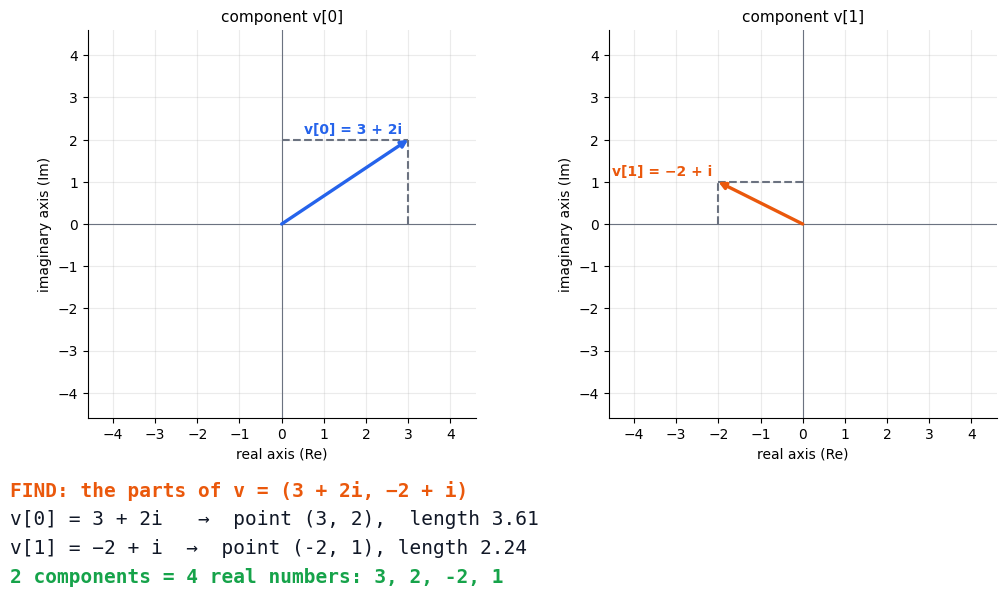

In [2]:
v = np.array([3 + 2j, -2 + 1j])                     # a complex vector with n = 2 components
print("v            =", v)
print("n            =", len(v), "components  ->", 2 * len(v), "real numbers")
print("v[0], v[1]   =", v[0], v[1], "   (counting starts at 0)")
print("v.real       =", v.real, "   v.imag =", v.imag)
print("abs(v)       =", abs(v), "   (length of each component)")
print("phases (deg) =", np.degrees(np.angle(v)))

fig, axs = plt.subplots(1, 2, figsize=(10.4, 5.0))
for k, (comp, col) in enumerate(zip(v, (BLUE, ORANGE))):
    ax = new_plane(lim=4.6, title=f"component v[{k}]", ax=axs[k], step=1)
    ax.plot([comp.real, comp.real], [0, comp.imag], "--", color=GRAY)               # drop lines show the two real numbers
    ax.plot([0, comp.real], [comp.imag, comp.imag], "--", color=GRAY)
    draw_arrow(ax, comp, col, f"v[{k}] = {cshort(comp)}", offset=(-0.15, 0.15), ha="right")
show_steps(f"FIND: the parts of v = {vshort(v)}", [
    f"v[0] = {cshort(v[0])}   →  point ({v[0].real:g}, {v[0].imag:g}),  length {abs(v[0]):.2f}",
    f"v[1] = {cshort(v[1])}  →  point ({v[1].real:g}, {v[1].imag:g}), length {abs(v[1]):.2f}",
    f"{len(v)} components = {2 * len(v)} real numbers: {v[0].real:g}, {v[0].imag:g}, {v[1].real:g}, {v[1].imag:g}"])

plt.show()

**R — Result.** `v` has 2 components, which is `2 · 2 = 4` real numbers (`n` lengths and `n` angles). A real vector is the special case where every imaginary part is 0.

<span style="color:#dc2626">**A qubit is a complex vector** in `ℂ²` whose squared lengths add up to 1: `|α|² + |β|² = 1`.</span> `n` qubits give `ℂ^(2ⁿ)`, a vector with `2ⁿ` components.

*Common mistake:* `v[1]` is the **second** component, because Python counts from 0.

### 2.2 Adding and subtracting vectors

**S — Situation.** Two states get combined all the time: in ML you add two embeddings, in a quantum circuit you add the amplitudes of two paths (interference, notebook 1, section 1.5).

**T — Task.** Add or subtract two complex vectors of the same size.

**A — Action.** <span style="color:#dc2626">Add **component by component**: the `k`-th arrow only ever meets the `k`-th arrow.</span> Nothing mixes between components.

$$(u + w)_k = u_k + w_k, \qquad (u - w)_k = u_k - w_k$$

- `u`, `w` — two vectors with the **same** number of components `n`
- `uₖ ± wₖ` — ordinary complex addition or subtraction of the `k`-th components: real part with real part, imaginary with imaginary (notebook 1, section 1.5)
- the **zero vector** (all components 0) changes nothing, and `−v` (every component negated) is the vector that gives back 0

In Python: **`u + w`** and **`u - w`** (numpy works component by component; the two sizes must match).

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take `u = (2 + i, −1 + 2i)` and `w = (1 + 2i, 2 − i)`. What are `u + w` and `u − w`?

</div>

u + w = [3.+3.j 1.+1.j]
u - w = [ 1.-1.j -3.+3.j]
component 0: abs(u)² = 5, abs(w)² = 5, but abs(u+w)² = 18   <- amplitudes add, squared lengths do not
component 1: abs(u)² = 5, abs(w)² = 5, but abs(u+w)² = 2   <- amplitudes add, squared lengths do not


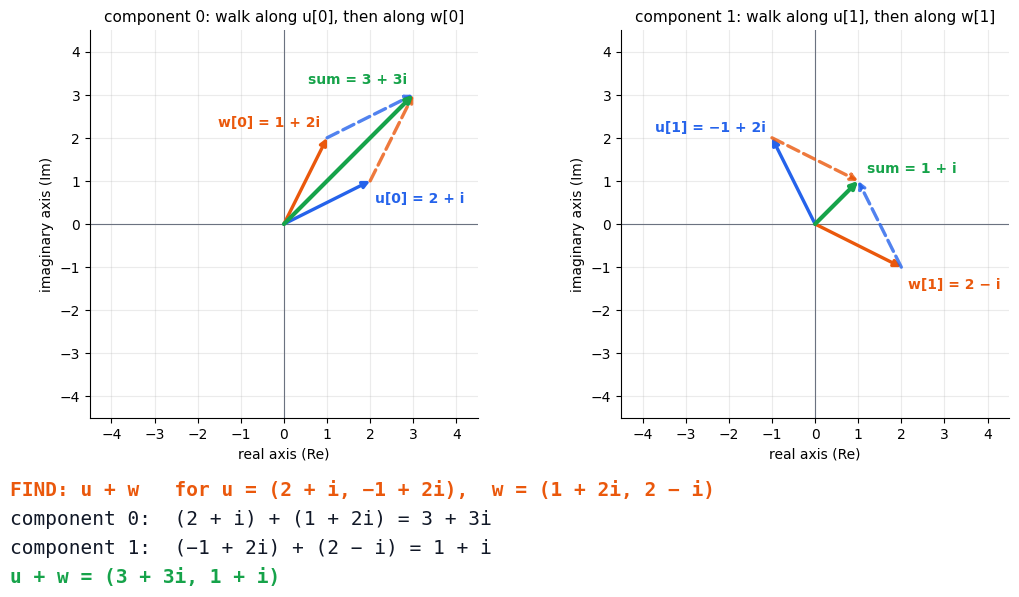

In [3]:
u = np.array([2 + 1j, -1 + 2j])
w = np.array([1 + 2j, 2 - 1j])
print("u + w =", u + w)
print("u - w =", u - w)
for k in range(2):
    print(f"component {k}: abs(u)² = {abs(u[k])**2:g}, abs(w)² = {abs(w[k])**2:g}, but abs(u+w)² = {abs(u[k] + w[k])**2:g}"
          "   <- amplitudes add, squared lengths do not")

fig, axs = plt.subplots(1, 2, figsize=(10.6, 5.2))
labels = {0: [(0.12, -0.5, "left"), (-0.15, 0.25, "right"), (-0.15, 0.25, "right")],
          1: [(-0.15, 0.15, "right"), (0.15, -0.5, "left"), (0.2, 0.2, "left")]}
for k, ax in enumerate(axs):
    new_plane(lim=4.5, title=f"component {k}: walk along u[{k}], then along w[{k}]", ax=ax, step=1)
    (ox, oy, oh), (px, py, ph), (sx, sy, sh) = labels[k]
    draw_arrow(ax, u[k], BLUE, f"u[{k}] = {cshort(u[k])}", offset=(ox, oy), ha=oh)
    draw_arrow(ax, w[k], ORANGE, f"w[{k}] = {cshort(w[k])}", offset=(px, py), ha=ph)
    draw_arrow(ax, u[k] + w[k], ORANGE, tail=u[k], linestyle="--", alpha=0.8)       # w[k] copied to the tip of u[k]
    draw_arrow(ax, u[k] + w[k], BLUE, tail=w[k], linestyle="--", alpha=0.8)         # u[k] copied to the tip of w[k]
    draw_arrow(ax, u[k] + w[k], GREEN, f"sum = {cshort(u[k] + w[k])}", lw=3, offset=(sx, sy), ha=sh)
show_steps(f"FIND: u + w   for u = {vshort(u)},  w = {vshort(w)}", [
    f"component 0:  ({cshort(u[0])}) + ({cshort(w[0])}) = {cshort(u[0] + w[0])}",
    f"component 1:  ({cshort(u[1])}) + ({cshort(w[1])}) = {cshort(u[1] + w[1])}",
    f"u + w = {vshort(u + w)}"])

plt.show()

**R — Result.** `u + w = (3 + 3i, 1 + i)` and `u − w = (1 − i, −3 + 3i)`. Each component is its own small addition: in the picture every plane shows "walk along `uₖ`, then along `wₖ`".

<span style="color:#dc2626">Adding vectors adds **amplitudes**, not probabilities.</span> In component 0 the squared lengths `5` and `5` become `18` (the arrows reinforce); in component 1 they become `2` (the arrows partly cancel). That difference is **interference**.

### 2.3 Scaling a vector by a complex number

**S — Situation.** In ML you scale an embedding by a number. In quantum computing the factor is **complex**, so it can also *turn* the vector.

**T — Task.** Multiply every component of a vector by one complex number `c` and predict what happens to the arrows.

**A — Action.** Multiply **each** component by `c`. From notebook 1, section 1.11: multiplying by `c` turns an arrow by the phase of `c` and stretches it by the length of `c`. <span style="color:#dc2626">**Every component gets the same turn and the same stretch.**</span>

$$(c\,v)_k = c\,v_k$$

- `c` — a complex number (a **scalar**: one number, not a list)
- `|c|` — the length of `c`: every arrow grows by this factor (`|c| = 2` doubles them)
- `arg c` — the phase of `c`: every arrow turns counter-clockwise by this angle

In Python: **`c * v`**.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take `c = 2i` (length 2, phase 90°) and `v = (1 + 0.5i, −1 + i)`. What is `c · v`?

</div>

c * v = [-1.+2.j -2.-2.j]
lengths  before: [1.118 1.414]   after: [2.236 2.828]   ratio: [2. 2.]   (= abs(c) = 2.0 )
turned by (deg): [90. 90.]   (= arg c = 90.0 )
ratio v[1]/v[0]  before: (-0.4+1.2j)   after: (-0.4+1.2j)   <- unchanged: the shape of the vector stays


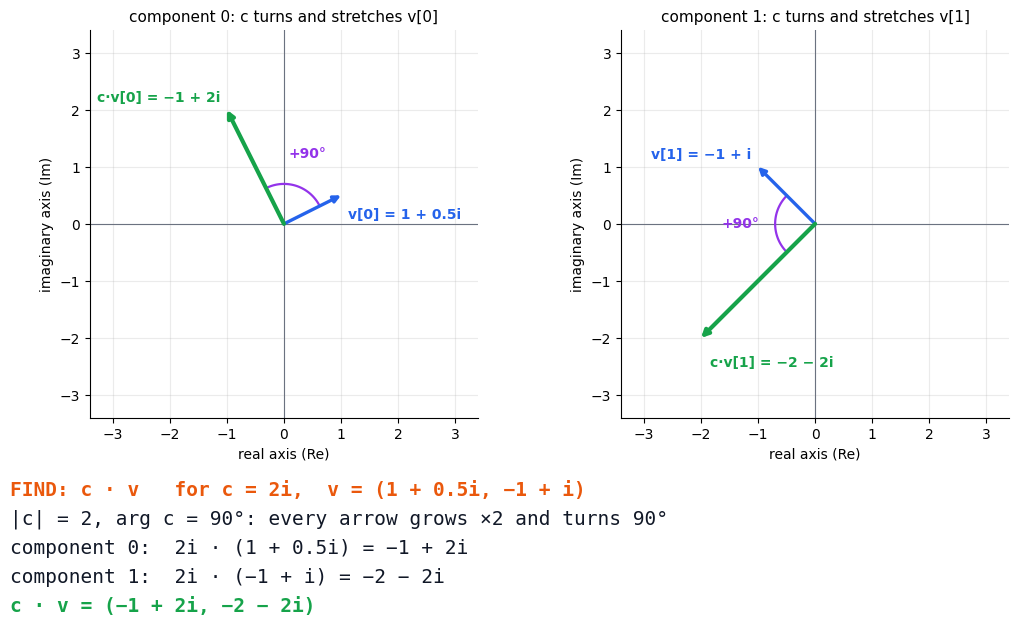

In [4]:
c = 2j
v = np.array([1 + 0.5j, -1 + 1j])
cv = c * v
print("c * v =", cv)
print("lengths  before:", abs(v), "  after:", abs(cv), "  ratio:", abs(cv) / abs(v), "  (= abs(c) =", abs(c), ")")
print("turned by (deg):", np.degrees(np.angle(cv / v)), "  (= arg c =", np.degrees(np.angle(c)), ")")
print("ratio v[1]/v[0]  before:", np.round(v[1] / v[0], 3), "  after:", np.round(cv[1] / cv[0], 3), "  <- unchanged: the shape of the vector stays")

fig, axs = plt.subplots(1, 2, figsize=(10.6, 5.2))
lab_v = [(0.12, -0.4, "left"), (-0.12, 0.15, "right")]
lab_cv = [(-0.12, 0.15, "right"), (0.15, -0.5, "left")]
for k, ax in enumerate(axs):
    new_plane(lim=3.4, title=f"component {k}: c turns and stretches v[{k}]", ax=ax, step=1)
    draw_arrow(ax, v[k], BLUE, f"v[{k}] = {cshort(v[k], 1)}", offset=lab_v[k][:2], ha=lab_v[k][2])
    draw_arrow(ax, cv[k], GREEN, f"c·v[{k}] = {cshort(cv[k])}", lw=3, offset=lab_cv[k][:2], ha=lab_cv[k][2])
    a0, a1 = np.angle(v[k]), np.angle(cv[k])
    a1 = a1 if a1 > a0 else a1 + 2 * np.pi
    draw_arc(ax, 0.7, a0, a1, color=PURPLE, label="+90°", label_radius=1.3)
show_steps(f"FIND: c · v   for c = {cshort(c)},  v = {vshort(v, 1)}", [
    "|c| = 2, arg c = 90°: every arrow grows ×2 and turns 90°",
    f"component 0:  {cshort(c)} · ({cshort(v[0], 1)}) = {cshort(cv[0])}",
    f"component 1:  {cshort(c)} · ({cshort(v[1])}) = {cshort(cv[1])}",
    f"c · v = {vshort(cv)}"])

plt.show()

**R — Result.** `c · v = (−1 + 2i, −2 − 2i)`: both arrows turned by 90° and became twice as long.

<span style="color:#dc2626">A complex scalar turns and stretches **all** arrows by the same amount.</span> So the *shape* of the vector (the ratio `v[1] / v[0]`, the angle between the arrows) does not change. If `|c| = 1`, the scalar only turns the arrows and keeps all lengths: that is exactly a **global phase**, the next point.

### 2.4 Global phase and relative phase

**S — Situation.** A qubit state `(α, β)` can be written in many ways that *look* different (arrows turned) but behave the same, and in other ways that look almost the same but behave differently.

**T — Task.** Decide which changes of phase a measurement can see, and which it cannot.

**A — Action.** There are two ways to turn arrows:

- **Global phase:** multiply the **whole** vector by `e^{iγ}`. <span style="color:#dc2626">**Every arrow turns by the same angle `γ`, so all lengths and the angle *between* the arrows stay.**</span>
- **Relative phase:** turn **only one** component. The angle between the arrows changes.

$$v \;\to\; e^{i\gamma}\,v \quad(\text{global}), \qquad (v_1, v_2) \;\to\; (v_1,\; e^{i\gamma}v_2) \quad(\text{relative})$$

- `γ` (gamma) — an angle in radians; `e^{iγ}` is a number of length 1 that turns by `γ` (notebook 1, section 1.10)
- the **relative phase** of two components is the angle between their arrows
- to *see* a relative phase you have to **mix** the two components. The Hadamard matrix `H` does this: it adds and subtracts them (divided by `√2`). In Python `Hg @ v`.

In Python: **`np.exp(1j * g) * v`** (global) and **`v * np.exp(1j * g * np.array([0, 1]))`** (turn only component 1).

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take `ψ = (1, i)/√2` and `γ = 90°`. Turn everything by `γ` (global), or turn only the second component (relative). Compare the probabilities, then mix with `H` and compare again.

</div>

original        probabilities = [0.5 0.5]   after mixing with H: [0.5 0.5]   angle between arrows = 90°
global phase    probabilities = [0.5 0.5]   after mixing with H: [0.5 0.5]   angle between arrows = 90°
relative phase  probabilities = [0.5 0.5]   after mixing with H: [0. 1.]   angle between arrows = 180°


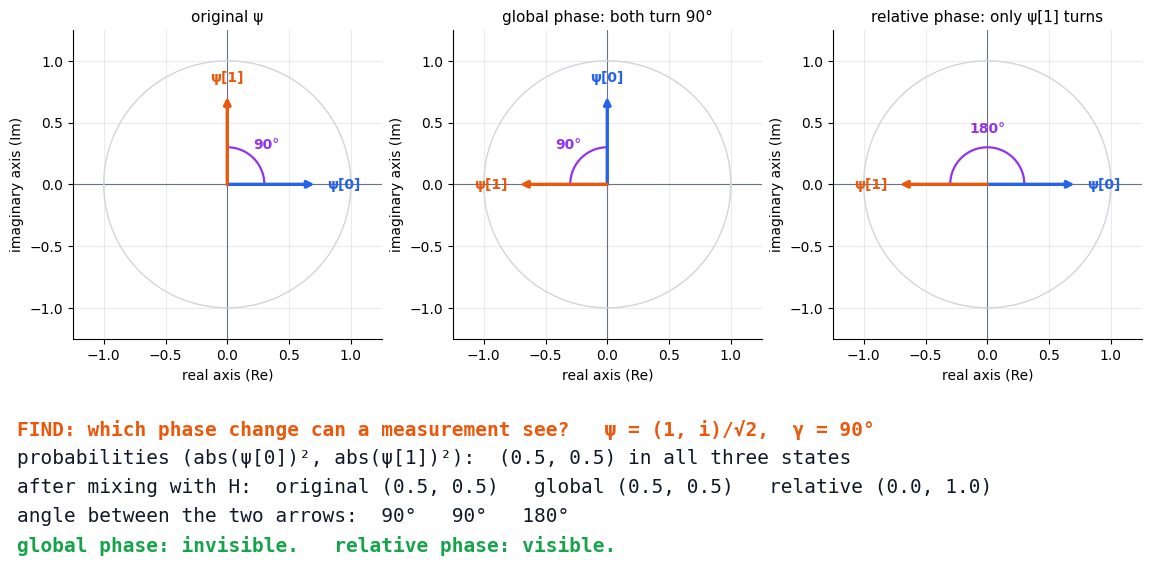

In [5]:
psi = np.array([1, 1j]) / np.sqrt(2)
g = np.pi / 2                                              # gamma = 90 degrees
glob = np.exp(1j * g) * psi                                # global phase: every component turns by gamma
rel = psi * np.exp(1j * g * np.array([0, 1]))              # relative phase: only component 1 turns
states = [("original", psi), ("global phase", glob), ("relative phase", rel)]

angle_between = lambda v: np.degrees(np.angle(v[1] / v[0])) % 360     # angle between the two arrows
for name, v in states:
    print(f"{name:15s} probabilities = {abs(v) ** 2}   after mixing with H: {abs(Hg @ v) ** 2}   angle between arrows = {angle_between(v):.0f}°")

fig, axs = plt.subplots(1, 3, figsize=(11.4, 4.4))
titles = ["original ψ", "global phase: both turn 90°", "relative phase: only ψ[1] turns"]
for ax, (name, v), title in zip(axs, states, titles):
    new_plane(lim=1.25, title=title, ax=ax, unit_circle=True)
    for k, col in enumerate((BLUE, ORANGE)):
        draw_arrow(ax, v[k], col)
        d = v[k] / abs(v[k])
        ax.text(v[k].real + 0.1 * d.real, v[k].imag + 0.1 * d.imag, f"ψ[{k}]", color=col, fontweight="bold",
                ha="left" if d.real > 0.1 else "right" if d.real < -0.1 else "center",
                va="bottom" if d.imag > 0.1 else "top" if d.imag < -0.1 else "center")
    a0, a1 = np.angle(v[0]), np.angle(v[1])
    a1 = a1 if a1 > a0 else a1 + 2 * np.pi
    draw_arc(ax, 0.3, a0, a1, color=PURPLE, label=f"{angle_between(v):.0f}°", label_radius=0.45)
p = [abs(v) ** 2 for _, v in states]
q = [abs(Hg @ v) ** 2 for _, v in states]
show_steps(f"FIND: which phase change can a measurement see?   ψ = (1, i)/√2,  γ = 90°", [
    f"probabilities (abs(ψ[0])², abs(ψ[1])²):  ({p[0][0]:.1f}, {p[0][1]:.1f}) in all three states",
    f"after mixing with H:  original ({q[0][0]:.1f}, {q[0][1]:.1f})   global ({q[1][0]:.1f}, {q[1][1]:.1f})   relative ({q[2][0]:.1f}, {q[2][1]:.1f})",
    f"angle between the two arrows:  {angle_between(psi):.0f}°   {angle_between(glob):.0f}°   {angle_between(rel):.0f}°",
    "global phase: invisible.   relative phase: visible."])

plt.show()

**R — Result.** Before mixing, all three states look identical: probabilities `(0.5, 0.5)`. After mixing with `H`, the original and the globally turned state still give `(0.5, 0.5)`, but the state with a relative phase gives `(0, 1)`: a certain outcome.

<span style="color:#dc2626">**Global phase cannot be observed; relative phase can.**</span> The relative phase decides whether two amplitudes **reinforce or cancel** when they are added (2.2). So two vectors that differ only by a global phase are **the same physical state**.

### 2.5 Complex conjugate of a vector

**S — Situation.** Quantum notation writes a state as a column `|v⟩` (a "ket") and its mirror as a row `⟨v|` (a "bra"). The mirror **conjugates every number**. You need it for the inner product, the next point.

**T — Task.** Conjugate a vector and see what changes.

**A — Action.** Conjugate **each component** (notebook 1, section 1.8): flip the sign of every imaginary part. <span style="color:#dc2626">**Every arrow is mirrored across the real axis.**</span>

$$\overline{v} = \left(\overline{v_1}, \dots, \overline{v_n}\right), \qquad \overline{a + bi} = a - bi$$

- `v̄` — the **conjugate vector** (also written `v*`)
- lengths stay the same, phases change sign, and conjugating twice gives `v` back
- the **bra** `⟨v|` is the conjugate vector written as a row (physicists call this the conjugate transpose, `v†`). A numpy 1-D array has no row or column, so **`v.conj()`** plays the role of the bra.

In Python: **`v.conj()`** or `np.conj(v)`.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take `v = (1 + 2i, 3 − i)`. What is `v̄`, and what happens to the lengths and the phases?

</div>

v        = [1.+2.j 3.-1.j]
v.conj() = [1.-2.j 3.+1.j]
lengths  : [2.236 3.162] -> [2.236 3.162]    (same)
phases   : [ 63.435 -18.435] -> [-63.435  18.435]    (sign flips)
conj twice == v        : True
conj(v[k]) * v[k]      = [ 5.+0.j 10.+0.j]   <- real, equals abs(v)**2 = [ 5. 10.]


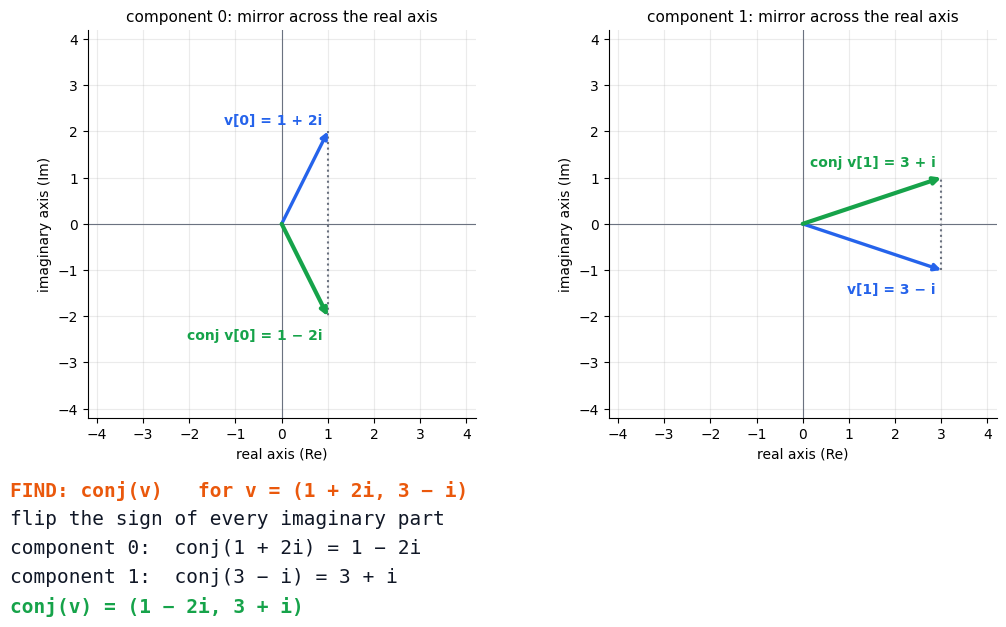

In [6]:
v = np.array([1 + 2j, 3 - 1j])
vbar = v.conj()
print("v        =", v)
print("v.conj() =", vbar)
print("lengths  :", abs(v), "->", abs(vbar), "   (same)")
print("phases   :", np.degrees(np.angle(v)), "->", np.degrees(np.angle(vbar)), "   (sign flips)")
print("conj twice == v        :", np.allclose(vbar.conj(), v))
print("conj(v[k]) * v[k]      =", vbar * v, "  <- real, equals abs(v)**2 =", abs(v) ** 2)

fig, axs = plt.subplots(1, 2, figsize=(10.4, 5.0))
lab_v = [(-0.12, 0.15, "right"), (-0.12, -0.5, "right")]
lab_c = [(-0.12, -0.5, "right"), (-0.12, 0.25, "right")]
for k, ax in enumerate(axs):
    new_plane(lim=4.2, title=f"component {k}: mirror across the real axis", ax=ax, step=1)
    ax.plot([v[k].real, v[k].real], [v[k].imag, -v[k].imag], ":", color=GRAY)
    draw_arrow(ax, v[k], BLUE, f"v[{k}] = {cshort(v[k])}", offset=lab_v[k][:2], ha=lab_v[k][2])
    draw_arrow(ax, vbar[k], GREEN, f"conj v[{k}] = {cshort(vbar[k])}", lw=3, offset=lab_c[k][:2], ha=lab_c[k][2])
show_steps(f"FIND: conj(v)   for v = {vshort(v)}", [
    "flip the sign of every imaginary part",
    f"component 0:  conj({cshort(v[0])}) = {cshort(vbar[0])}",
    f"component 1:  conj({cshort(v[1])}) = {cshort(vbar[1])}",
    f"conj(v) = {vshort(vbar)}"])

plt.show()

**R — Result.** `v̄ = (1 − 2i, 3 + i)`: the same lengths, mirrored arrows.

<span style="color:#dc2626">**Why this matters: `conj(vₖ) · vₖ = |vₖ|²` is always real and never negative.**</span> Adding these up over all components gives the squared length of the whole vector. That is the idea behind the inner product (2.6) and the norm (2.7).

### 2.6 Inner product

**S — Situation.** To compare two states ("how similar are they?", "are they orthogonal?") or to get a measurement probability you need **one number from two vectors**. In ML that is the dot product.

**T — Task.** Compute the overlap `⟨u|v⟩` of two complex vectors.

**A — Action.** Multiply the matching components, <span style="color:#dc2626">**conjugating the first vector**</span>, and add everything up:

$$\langle u|v\rangle = \sum_k \overline{u_k}\, v_k$$

- `ūₖ` — the conjugate of the `k`-th component of `u` (2.5)
- the result is **one complex number**, not a vector
- its **size** says how strongly the two vectors overlap, its **angle** is a relative phase
- `⟨u|v⟩ = 0` means `u` and `v` are **orthogonal**; `⟨v|u⟩` is the conjugate of `⟨u|v⟩`
- the conjugate is not decoration: without it `⟨u|u⟩` could be 0 or negative (see the code below)

In Python: **`np.vdot(u, v)`**. It conjugates the first argument for you. Do **not** use `u @ v` or `np.dot(u, v)`: they do not conjugate.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take `u = (2, i)` and `v = (1 + i, 3)`. What is `⟨u|v⟩`?

</div>

conj(u)           = [2.+0.j 0.-1.j]
conj(u[k]) * v[k] = [2.+2.j 0.-3.j]    <- one product per component
<u|v> = np.vdot(u, v) = (2-1j)    = sum of the products = (2-1j)
<v|u> = np.vdot(v, u) = (2+1j)    = conjugate of <u|v>
WRONG, no conjugate: u @ v = (2+5j)

for a = (1, i)/√2 and b = (1, −i)/√2:
<a|b>          = 0j    -> orthogonal
<a|a> (vdot)   = (1+0j)    -> length² 1, as it should be
a @ a (wrong)  = 0j    -> 'length' 0: nonsense without the conjugate


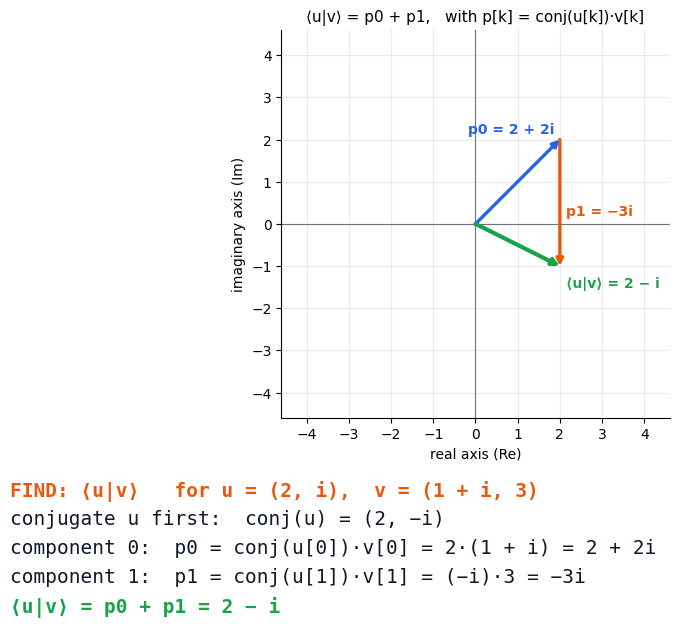

In [7]:
u = np.array([2, 1j])
v = np.array([1 + 1j, 3])
p = u.conj() * v                                   # one product per component
print("conj(u)           =", clean(u.conj()))
print("conj(u[k]) * v[k] =", p, "   <- one product per component")
print("<u|v> = np.vdot(u, v) =", np.vdot(u, v), "   = sum of the products =", p.sum())
print("<v|u> = np.vdot(v, u) =", np.vdot(v, u), "   = conjugate of <u|v>")
print("WRONG, no conjugate: u @ v =", u @ v)

# an orthogonal pair, and why the conjugate is not optional
a = np.array([1, 1j]) / np.sqrt(2)
b = np.array([1, -1j]) / np.sqrt(2)
print("\nfor a = (1, i)/√2 and b = (1, −i)/√2:")
print("<a|b>          =", clean(np.vdot(a, b)), "   -> orthogonal")
print("<a|a> (vdot)   =", clean(np.vdot(a, a)), "   -> length² 1, as it should be")
print("a @ a (wrong)  =", clean(a @ a), "   -> 'length' 0: nonsense without the conjugate")

ax = new_plane(lim=4.6, title="⟨u|v⟩ = p0 + p1,   with p[k] = conj(u[k])·v[k]", figsize=(6.4, 5.8), step=1)
draw_arrow(ax, p[0], BLUE, f"p0 = {cshort(p[0])}", offset=(-0.12, 0.15), ha="right")
draw_arrow(ax, p[0] + p[1], ORANGE, f"p1 = {cshort(p[1])}", tail=p[0], offset=(0.15, 1.2))
draw_arrow(ax, np.vdot(u, v), GREEN, f"⟨u|v⟩ = {cshort(np.vdot(u, v))}", lw=3, offset=(0.15, -0.5))
show_steps(f"FIND: ⟨u|v⟩   for u = {vshort(u)},  v = {vshort(v)}", [
    f"conjugate u first:  conj(u) = {vshort(u.conj())}",
    f"component 0:  p0 = conj(u[0])·v[0] = {cshort(u.conj()[0])}·({cshort(v[0])}) = {cshort(p[0])}",
    f"component 1:  p1 = conj(u[1])·v[1] = ({cshort(u.conj()[1])})·{cshort(v[1])} = {cshort(p[1])}",
    f"⟨u|v⟩ = p0 + p1 = {cshort(np.vdot(u, v))}"])

plt.show()

**R — Result.** `⟨u|v⟩ = 2 − i`: two products `2 + 2i` and `−3i` placed tip to tail end at `2 − i`. The sum of the products is **one** number.

<span style="color:#dc2626">**Always use `np.vdot(u, v)` for the inner product.**</span> The check in the code shows why: for the orthogonal pair `a`, `b` the right answer is `0`, and for a single vector `a @ a` would claim the length is 0.

| Fact | Statement |
|---|---|
| Orthogonal | $\langle u\vert v\rangle = 0$ |
| Cauchy–Schwarz | $\lvert\langle u\vert v\rangle\rvert \le \lVert u\rVert\,\lVert v\rVert$ |
| Unit vector (a valid quantum state) | $\lVert v\rVert = 1$ |
| **Born rule preview** | probability of outcome $i$ = $\lvert\langle i\vert\psi\rangle\rvert^2$ |

### 2.7 Norm: the length of a vector

**S — Situation.** A quantum state must have length 1, and in ML the length of an embedding decides how large its scores are. You need the **length of a complex vector**.

**T — Task.** Compute the length `‖v‖` of a complex vector.

**A — Action.** Add the **squared lengths** of the components and take the square root. <span style="color:#dc2626">**The phase of a component never matters.**</span>

$$\lVert v\rVert=\sqrt{\langle v|v\rangle}=\sqrt{\textstyle\sum_k \lvert v_k\rvert^2}$$

- `‖v‖` — the **norm** (length) of `v`
- `|vₖ|` — the length of the `k`-th component (notebook 1, section 1.6)
- `⟨v|v⟩ = Σ conj(vₖ)·vₖ = Σ |vₖ|²` is real and never negative: that is why the inner product conjugates the first vector

| Property | Statement |
|---|---|
| Positive | $\lVert v\rVert\ge0$, and $=0$ only for $v=0$ |
| Homogeneous | $\lVert c\,v\rVert=\lvert c\rvert\,\lVert v\rVert$ |
| Triangle inequality | $\lVert u+v\rVert\le\lVert u\rVert+\lVert v\rVert$ |
| **Phase-blind** | $\lVert e^{i\gamma}v\rVert=\lVert v\rVert$ |

In Python: **`np.linalg.norm(v)`** (the same as `np.sqrt(np.vdot(v, v).real)`).

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take `v = (3, 4i)`. What is `‖v‖`?

</div>

abs(v)**2       = [ 9. 16.]    (squared length of each component)
sum             = 25.0
sqrt(<v|v>)     = 5.0    (our helper)
np.linalg.norm  = 5.0    (built in, same number)

properties, for w = (1 + 2i, 2 − i) and c = 2 + i:
||c w|| = |c| ||w||      : 7.0711 = 7.0711
triangle ||v+w|| <= sum  : 5.7446 <= 8.1623
global phase keeps norm  : 5.0 = 5.0


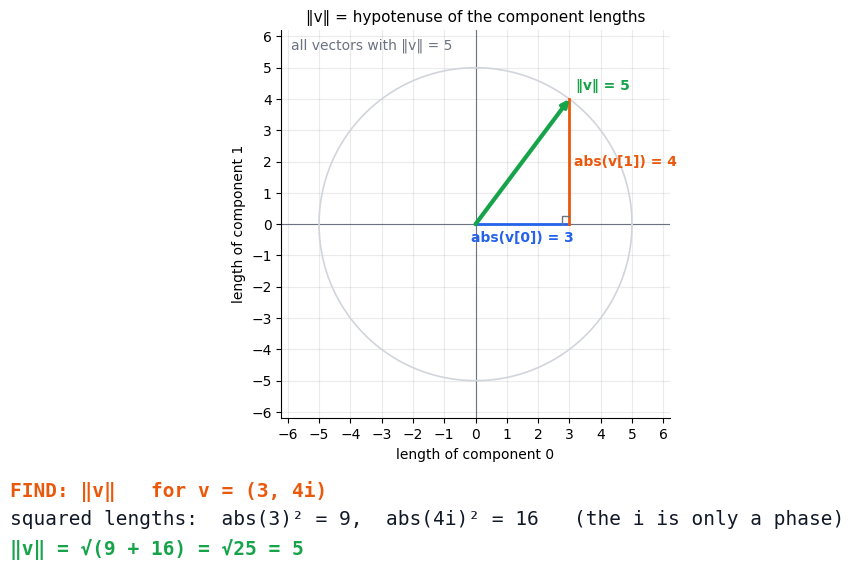

In [8]:
v = np.array([3, 4j])
print("abs(v)**2       =", abs(v) ** 2, "   (squared length of each component)")
print("sum             =", (abs(v) ** 2).sum())
print("sqrt(<v|v>)     =", norm(v), "   (our helper)")
print("np.linalg.norm  =", np.linalg.norm(v), "   (built in, same number)")

w, c = np.array([1 + 2j, 2 - 1j]), 2 + 1j
print("\nproperties, for w = (1 + 2i, 2 − i) and c = 2 + i:")
print("||c w|| = |c| ||w||      :", round(norm(c * w), 4), "=", round(abs(c) * norm(w), 4))
print("triangle ||v+w|| <= sum  :", round(norm(v + w), 4), "<=", round(norm(v) + norm(w), 4))
print("global phase keeps norm  :", norm(np.exp(1j * 0.7) * v), "=", norm(v))

ax = new_plane(lim=6.2, title="‖v‖ = hypotenuse of the component lengths", figsize=(5.8, 5.6), step=1)
t = np.linspace(0, 2 * np.pi, 300)
ax.plot(5 * np.cos(t), 5 * np.sin(t), color="#d1d5db", lw=1.2)
ax.text(-5.9, 5.6, "all vectors with ‖v‖ = 5", color=GRAY)
ax.plot([0, 3], [0, 0], color=BLUE, lw=2)
ax.plot([3, 3], [0, 4], color=ORANGE, lw=2)
ax.plot([2.75, 2.75, 3], [0, 0.25, 0.25], color=GRAY, lw=1)                   # right-angle marker
draw_arrow(ax, 3 + 4j, GREEN, lw=3)
ax.text(1.5, -0.55, "abs(v[0]) = 3", color=BLUE, ha="center", fontweight="bold")
ax.text(3.15, 2.0, "abs(v[1]) = 4", color=ORANGE, va="center", fontweight="bold")
ax.text(3.2, 4.3, "‖v‖ = 5", color=GREEN, fontweight="bold")
ax.set_xlabel("length of component 0")
ax.set_ylabel("length of component 1")
show_steps(f"FIND: ‖v‖   for v = {vshort(v)}", [
    "squared lengths:  abs(3)² = 9,  abs(4i)² = 16   (the i is only a phase)",
    "‖v‖ = √(9 + 16) = √25 = 5"])

plt.show()

**R — Result.** `‖v‖ = 5`. The two component lengths `3` and `4` are the legs of a right triangle, and `‖v‖` is its hypotenuse.

<span style="color:#dc2626">**The phase never changes the norm:**</span> `|4i| = |4| = 4`, and turning the whole vector by any angle leaves `‖v‖` the same (checked in the code). That is why a quantum state can be turned by a global phase without changing anything.

### 2.8 Normalization

**S — Situation.** A quantum state must have length 1, because the probabilities of all outcomes add up to 1 (the **Born rule**). Data usually does not have length 1: an embedding before L2 normalization is just a vector of some length.

**T — Task.** Turn a vector into a valid state of length 1, without changing what it "points at".

**A — Action.** <span style="color:#dc2626">**Divide the vector by its length.**</span>

$$\hat v = \frac{v}{\lVert v\rVert}$$

- `v̂` — the **unit vector** (written `v_hat` in the picture): same direction, length 1
- normalizing removes **only the overall size**. The ratios of the amplitudes and the relative phases stay. Vectors that differ by a nonzero complex factor describe the same state.
- the Born rule: outcome `k` has probability `|v̂ₖ|² = |vₖ|² / ‖v‖²`, and these add up to 1
- the zero vector cannot be normalized (division by 0)

In Python: **`v / np.linalg.norm(v)`**.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take `v = (3, 4i)` from the previous point. Normalize it and read off the probabilities.

</div>

||v||        = 5.0
v / ||v||    = [0.6+0.j  0. +0.8j]    norm = 1.0
probabilities abs(vhat)**2 = [0.36 0.64]    sum = 1.0
without normalizing: abs(v)**2 = [ 9. 16.]    sum = 25.0   <- not probabilities
relative phase before: 90.0 deg    after: 90.0 deg   (unchanged)


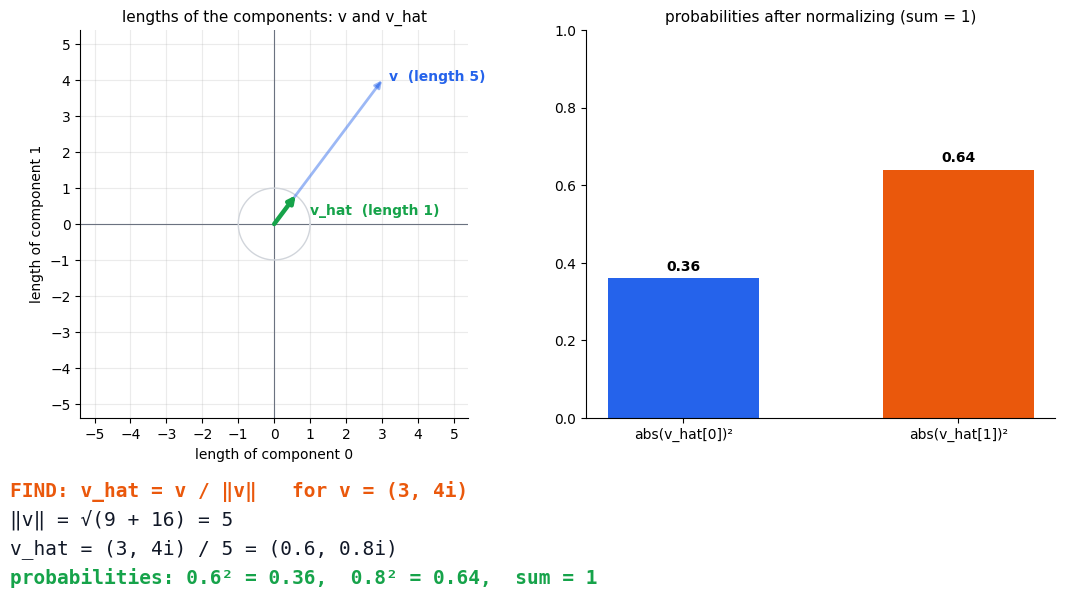

In [9]:
v = np.array([3, 4j])
vhat = normalize(v)
print("||v||        =", norm(v))
print("v / ||v||    =", vhat, "   norm =", norm(vhat))
print("probabilities abs(vhat)**2 =", abs(vhat) ** 2, "   sum =", round((abs(vhat) ** 2).sum(), 6))
print("without normalizing: abs(v)**2 =", abs(v) ** 2, "   sum =", (abs(v) ** 2).sum(), "  <- not probabilities")
print("relative phase before:", np.degrees(np.angle(v[1] / v[0])), "deg    after:", np.degrees(np.angle(vhat[1] / vhat[0])), "deg   (unchanged)")

fig, axs = plt.subplots(1, 2, figsize=(10.6, 5.0), gridspec_kw={"width_ratios": [1.15, 1]})
ax = new_plane(lim=5.4, title="lengths of the components: v and v_hat", ax=axs[0], unit_circle=True, step=1)
ax.set_xlabel("length of component 0")
ax.set_ylabel("length of component 1")
draw_arrow(ax, 3 + 4j, BLUE, "v  (length 5)", alpha=0.45, lw=2, offset=(0.2, 0.0))
draw_arrow(ax, 0.6 + 0.8j, GREEN, "v_hat  (length 1)", lw=3.2, offset=(0.4, -0.55))
ax = axs[1]
bars = ax.bar(["abs(v_hat[0])²", "abs(v_hat[1])²"], abs(vhat) ** 2, color=[BLUE, ORANGE], width=0.55)
for rect, val in zip(bars, abs(vhat) ** 2):
    ax.text(rect.get_x() + rect.get_width() / 2, val + 0.02, f"{val:.2f}", ha="center", fontweight="bold")
ax.set_ylim(0, 1.0)
ax.set_title("probabilities after normalizing (sum = 1)", fontsize=11)
show_steps(f"FIND: v_hat = v / ‖v‖   for v = {vshort(v)}", [
    "‖v‖ = √(9 + 16) = 5",
    f"v_hat = {vshort(v)} / 5 = {vshort(vhat, 1)}",
    f"probabilities: {abs(vhat[0]):.1f}² = {abs(vhat[0]) ** 2:.2f},  {abs(vhat[1]):.1f}² = {abs(vhat[1]) ** 2:.2f},  sum = {(abs(vhat) ** 2).sum():.0f}"])

plt.show()

**R — Result.** `v̂ = (0.6, 0.8i)` with probabilities `0.36` and `0.64`, adding up to 1. Without normalizing, the "probabilities" `9` and `16` add up to 25, which is nonsense.

<span style="color:#dc2626">**Normalizing changes only the length, never the relative phase.**</span> So `(3, 4i)` and `(0.6, 0.8i)` describe **the same state**, and only the normalized one can be used to read probabilities. A **normalized quantum state is exactly a unit vector.**

### 2.9 Angle and overlap between two states

**S — Situation.** Two states can be nearly the same or completely different (orthogonal). If you prepare `v` and then ask "is it `u`?", the chance of "yes" is their **overlap**.

**T — Task.** Measure how far apart two states are, with an angle and with an overlap probability.

**A — Action.** The inner product gives the angle `θ` between the two states:

$$\cos\theta=\frac{\lvert\langle u|v\rangle\rvert}{\lVert u\rVert\,\lVert v\rVert},\qquad \theta\in[0^\circ,90^\circ]$$

- `|⟨u|v⟩|` — the size of the inner product (the modulus makes the angle blind to a global phase)
- for **unit** vectors the **overlap probability** is `|⟨u|v⟩|² = cos² θ`
- orthogonal states have `θ = 90°` and overlap 0; identical states have `θ = 0°` and overlap 1

> **Hilbert-space angle vs. Bloch-sphere angle.** On the Bloch sphere the same pair of states is **twice** as far apart. `|0⟩` and `|1⟩` are orthogonal (90° in Hilbert space) but sit at opposite poles (180° on the sphere).

In Python: **`abs(np.vdot(u, v))**2`** for the overlap, and `np.degrees(np.arccos(...))` for the angle.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: how far apart are `|0⟩ = (1, 0)` and `|+⟩ = (1, 1)/√2`? Find their overlap probability and the angle.

</div>

pair                        overlap  Hilbert angle  Bloch angle
|0>, |1>                      0.000           90.0        180.0
|0>, |+>                      0.500           45.0         90.0
|+>, |->                      0.000           90.0        180.0
|0>, |+i>                     0.500           45.0         90.0
|+>, i|+>  (same state)       1.000            0.0          0.0


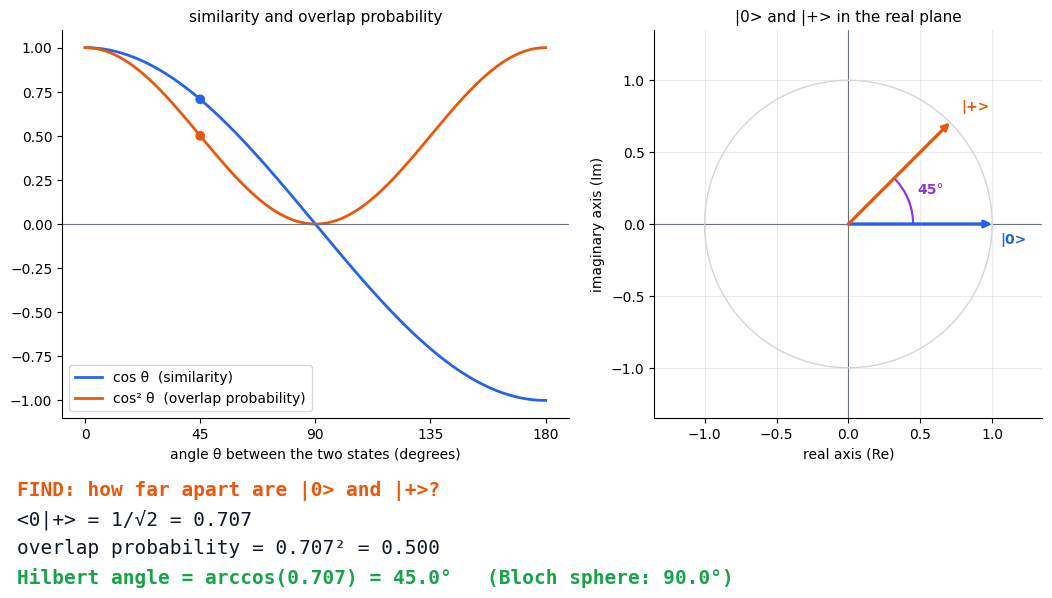

In [10]:
def state_angle(a, b):
    """Angle in degrees between two states: cos(theta) = abs(<a|b>) / (||a|| ||b||)."""
    c = abs(np.vdot(a, b)) / (norm(a) * norm(b))
    return np.degrees(np.arccos(np.clip(c, 0, 1)))


def bloch(psi):
    """Point (x, y, z) of a state on the Bloch sphere."""
    a, b = normalize(psi)
    return np.array([2 * (np.conj(a) * b).real, 2 * (np.conj(a) * b).imag, abs(a) ** 2 - abs(b) ** 2])


pairs = {"|0>, |1>": (ket0, ket1), "|0>, |+>": (ket0, plus), "|+>, |->": (plus, minus),
         "|0>, |+i>": (ket0, plus_i), "|+>, i|+>  (same state)": (plus, 1j * plus)}
print(f"{'pair':26s} {'overlap':>8s} {'Hilbert angle':>14s} {'Bloch angle':>12s}")
for name, (a, b) in pairs.items():
    bloch_angle = np.degrees(np.arccos(np.clip(bloch(a) @ bloch(b), -1, 1)))
    print(f"{name:26s} {abs(np.vdot(a, b)) ** 2:8.3f} {state_angle(a, b):14.1f} {bloch_angle:12.1f}")

ov = np.vdot(ket0, plus)
th = state_angle(ket0, plus)
t = np.linspace(0, np.pi, 300)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
ax = axs[0]
ax.plot(np.degrees(t), np.cos(t), color=BLUE, lw=2, label="cos θ  (similarity)")
ax.plot(np.degrees(t), np.cos(t) ** 2, color=ORANGE, lw=2, label="cos² θ  (overlap probability)")
ax.scatter([45, 45], [np.cos(np.pi / 4), 0.5], color=[BLUE, ORANGE], zorder=3)
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xticks([0, 45, 90, 135, 180])
ax.set_xlabel("angle θ between the two states (degrees)")
ax.legend(loc="lower left")
ax.set_title("similarity and overlap probability", fontsize=11)
ax = new_plane(lim=1.35, title="|0> and |+> in the real plane", ax=axs[1], unit_circle=True)
draw_arrow(ax, 1, BLUE, "|0>", offset=(0.06, -0.14))
draw_arrow(ax, np.exp(1j * np.pi / 4), ORANGE, "|+>", offset=(0.08, 0.08))
draw_arc(ax, 0.45, 0, np.pi / 4, color=PURPLE, label=f"{th:.0f}°", label_radius=0.62)
show_steps("FIND: how far apart are |0> and |+>?", [
    f"<0|+> = 1/√2 = {ov.real:.3f}",
    f"overlap probability = {ov.real:.3f}² = {abs(ov) ** 2:.3f}",
    f"Hilbert angle = arccos({ov.real:.3f}) = {th:.1f}°   (Bloch sphere: {2 * th:.1f}°)"])

plt.show()

**R — Result.** `⟨0|+⟩ = 0.707`, so the overlap probability is `0.5` and the angle is `45°` (`90°` on the Bloch sphere). The table above shows more pairs: orthogonal states overlap 0, and `|+⟩` and `i|+⟩` have angle 0 because they are the same state (a global phase).

<span style="color:#dc2626">**The overlap `|⟨u|v⟩|²` is the probability of finding state `u` in state `v`.**</span> It is blind to a global phase, which is exactly what we want.

### 2.10 Examples for an ML engineer

Three places where the ideas of this notebook already live in your ML toolbox: the FFT (a complex vector), cosine similarity (an overlap) and L2-normalized embeddings (a quantum state).

#### 2.10a The Fourier transform is a complex vector

**S — Situation.** `np.fft.fft(signal)` is everywhere in ML (audio, time series, spectrogram features). Its output is a **complex vector**.

**T — Task.** Show that delaying a signal in time changes **only the phases** of that vector, not its magnitudes.

**A — Action.** Entry `F[k]` is one complex number for frequency number `k`: its **length** is "how much of this frequency", its **phase** is "where this wave sits in time". Delaying the signal by `s` samples multiplies `F[k]` by a number of length 1, which only turns the arrow:

$$F_k \;\to\; e^{-2\pi i\,k s/n}\,F_k$$

- `n` — the number of samples, `k` — the frequency number, `s` — the delay in samples
- `e^{-2πi·k·s/n}` — a rotation (notebook 1, section 1.10); its length is 1, so the magnitude is unchanged

<span style="color:#dc2626">**Magnitudes are observable, phases are hidden until things interfere**</span>: the same split as in a qubit.

In Python: **`np.fft.fft(x)`** and `np.roll(x, s)` (delay by `s` samples).

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: a signal with two frequencies (3 and 7 cycles in 64 samples), delayed by 5 samples. Compare the FFT vectors of the signal and of the delayed signal.

</div>

F is a complex vector: complex128 (32,)
magnitudes equal after the delay: True
bin 3: arrow turned by   -84.4°    expected -2π·k·s/n =   -84.4°
bin 7: arrow turned by   163.1°    expected -2π·k·s/n =   163.1°


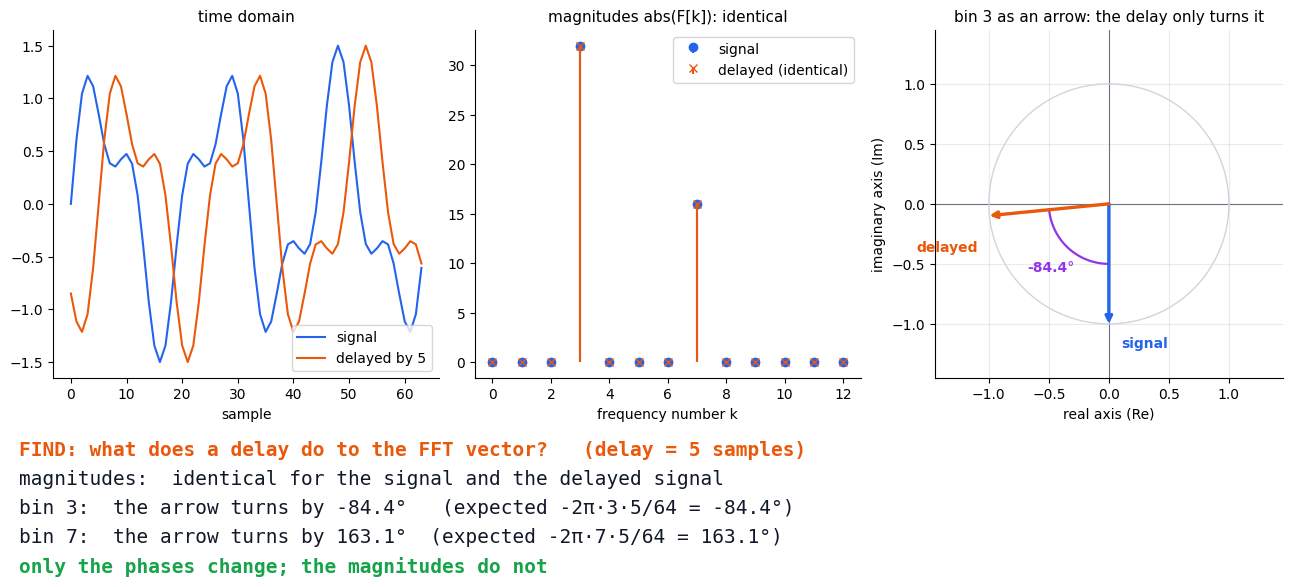

In [11]:
n, shift = 64, 5
tt = np.arange(n)
signal = np.sin(2 * np.pi * 3 * tt / n) + 0.5 * np.sin(2 * np.pi * 7 * tt / n)    # two frequencies: 3 and 7 cycles
shifted = np.roll(signal, shift)                                                   # the same signal, delayed by 5 samples

F, Fs = np.fft.fft(signal)[: n // 2], np.fft.fft(shifted)[: n // 2]                # complex vectors with 32 components
wrap = lambda deg: (deg + 180) % 360 - 180                                         # angle in (-180, 180]
print("F is a complex vector:", F.dtype, F.shape)
print("magnitudes equal after the delay:", np.allclose(abs(F), abs(Fs)))
turn = {}
for k in (3, 7):                                                                   # only these two bins carry signal
    turn[k] = np.degrees(np.angle(Fs[k] / F[k]))
    expected = wrap(np.degrees(-2 * np.pi * k * shift / n))
    print(f"bin {k}: arrow turned by {wrap(turn[k]):7.1f}°    expected -2π·k·s/n = {expected:7.1f}°")

fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
axs[0].plot(signal, color=BLUE, label="signal")
axs[0].plot(shifted, color=ORANGE, label="delayed by 5")
axs[0].set_title("time domain", fontsize=11)
axs[0].set_xlabel("sample")
axs[0].legend(loc="lower right")
axs[1].stem(abs(F)[:13], linefmt=BLUE, markerfmt="o", basefmt=" ", label="signal")
axs[1].stem(abs(Fs)[:13], linefmt=ORANGE, markerfmt="x", basefmt=" ", label="delayed (identical)")
axs[1].set_title("magnitudes abs(F[k]): identical", fontsize=11)
axs[1].set_xlabel("frequency number k")
axs[1].legend(loc="upper right")
ax = new_plane(lim=1.45, title="bin 3 as an arrow: the delay only turns it", ax=axs[2], unit_circle=True)
f3, f3s = F[3] / abs(F[3]), Fs[3] / abs(Fs[3])
draw_arrow(ax, f3, BLUE, "signal", offset=(0.1, -0.2))
draw_arrow(ax, f3s, ORANGE, "delayed", offset=(-0.1, -0.3), ha="right")
a0, a1 = np.angle(f3), np.angle(f3s)
draw_arc(ax, 0.5, a1, a0, color=PURPLE, label=f"{wrap(turn[3]):.1f}°", label_radius=0.72)
show_steps("FIND: what does a delay do to the FFT vector?   (delay = 5 samples)", [
    "magnitudes:  identical for the signal and the delayed signal",
    f"bin 3:  the arrow turns by {wrap(turn[3]):.1f}°   (expected -2π·3·5/64 = {wrap(np.degrees(-2 * np.pi * 3 * shift / n)):.1f}°)",
    f"bin 7:  the arrow turns by {wrap(turn[7]):.1f}°  (expected -2π·7·5/64 = {wrap(np.degrees(-2 * np.pi * 7 * shift / n)):.1f}°)",
    "only the phases change; the magnitudes do not"])

plt.show()

**R — Result.** The magnitudes are identical; bin 3 turned by `−84.4°` and bin 7 by `163.1°` (that is `−196.9°`, wrapped into the range −180° to 180°), exactly as the formula predicts. Only the phases moved.

<span style="color:#dc2626">A feature built from magnitudes, like a power spectrum `abs(F)**2`, cannot see the delay.</span> A feature that keeps the phases can. Same in a qubit: probabilities (magnitudes) are visible, relative phases are not, until the amplitudes are added.

#### 2.10b Cosine similarity is an overlap

**S — Situation.** In ML you compare embeddings with **cosine similarity**. For complex embeddings (FFT features, ComplEx knowledge-graph embeddings) and for quantum states the right comparison is the **inner product** (2.6).

**T — Task.** Check that cosine similarity *is* the inner product of the normalized vectors, and that for complex vectors only `np.vdot` gives the right overlap: **1 for the same state, 0 for orthogonal states.**

**A — Action.** For real embeddings: `cos-sim(a, b) = ⟨â|b̂⟩` with `â = a / ‖a‖`. For complex unit vectors the overlap is `|⟨a|b⟩|`, computed with **`np.vdot`** (it conjugates the first vector). Two properties define a good overlap:

- <span style="color:#dc2626">**the same state, even turned by a global phase `e^{iγ}`, has overlap exactly 1**</span>
- orthogonal states have overlap 0

The product without a conjugate, `a @ b`, has neither property.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take a random complex embedding `a` of length 1 and its copy `a·e^{iγ}` with `γ = 1.1` (the same state), and the orthogonal pair `(1, i)/√2`, `(1, −i)/√2`. Which product gives overlap 1 for the first pair and 0 for the second?

</div>

cosine similarity : -0.1753
<a_hat|b_hat>     : -0.1753    (the same number)

same state:       abs(vdot(a, a e^{ig})) = 1.0    abs(a @ (a e^{ig})) = 0.691    (should be 1)
orthogonal pair:  abs(vdot(p, q))        = 0.0    abs(p @ q)          = 1.0    (should be 0)


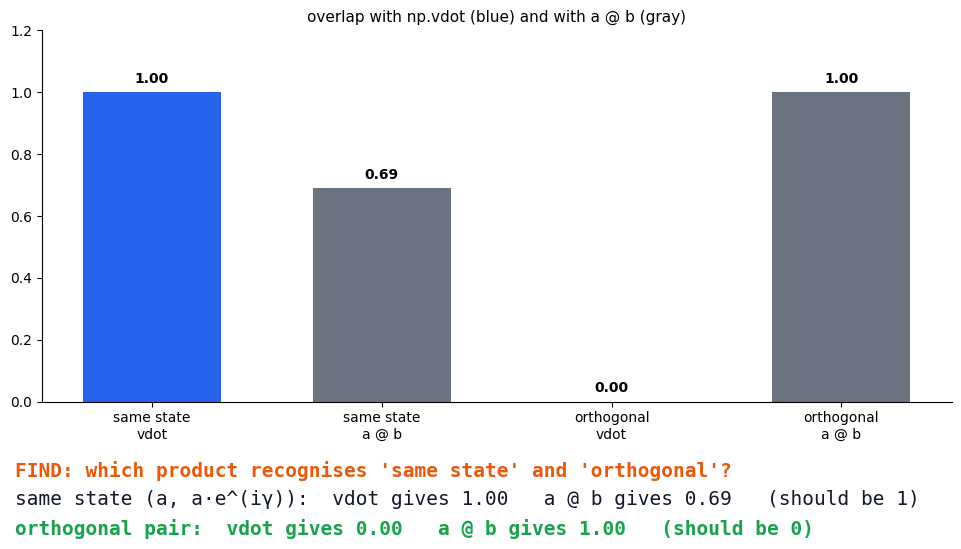

In [12]:
rng = np.random.default_rng(1)
a_r, b_r = rng.normal(size=8), rng.normal(size=8)                           # real embeddings
print("cosine similarity :", round(a_r @ b_r / (np.linalg.norm(a_r) * np.linalg.norm(b_r)), 4))
print("<a_hat|b_hat>     :", round(float(np.vdot(normalize(a_r), normalize(b_r))), 4), "   (the same number)")

a = normalize(rng.normal(size=8) + 1j * rng.normal(size=8))                 # a complex embedding of length 1
a_g = np.exp(1j * 1.1) * a                                                  # the SAME state, with a global phase
p, q = np.array([1, 1j]) / np.sqrt(2), np.array([1, -1j]) / np.sqrt(2)      # two orthogonal states
vals = {"same state\nvdot": abs(np.vdot(a, a_g)), "same state\na @ b": abs(a @ a_g),
        "orthogonal\nvdot": abs(np.vdot(p, q)), "orthogonal\na @ b": abs(p @ q)}
v1, v2, v3, v4 = vals.values()
print("\nsame state:       abs(vdot(a, a e^{ig})) =", round(v1, 3), "   abs(a @ (a e^{ig})) =", round(v2, 3), "   (should be 1)")
print("orthogonal pair:  abs(vdot(p, q))        =", round(v3, 3), "   abs(p @ q)          =", round(v4, 3), "   (should be 0)")

fig, ax = plt.subplots(figsize=(7.4, 4.4))
bars = ax.bar(list(vals), list(vals.values()), color=[BLUE, GRAY, BLUE, GRAY], width=0.6)
for rect, val in zip(bars, vals.values()):
    ax.text(rect.get_x() + rect.get_width() / 2, val + 0.03, f"{val:.2f}", ha="center", fontweight="bold")
ax.set_ylim(0, 1.2)
ax.set_title("overlap with np.vdot (blue) and with a @ b (gray)", fontsize=11)
show_steps("FIND: which product recognises 'same state' and 'orthogonal'?", [
    f"same state (a, a·e^(iγ)):  vdot gives {v1:.2f}   a @ b gives {v2:.2f}   (should be 1)",
    f"orthogonal pair:  vdot gives {v3:.2f}   a @ b gives {v4:.2f}   (should be 0)"])

plt.show()

**R — Result.** With the conjugate both checks pass: a state and its globally turned copy overlap exactly `1.00`, and the orthogonal pair overlaps `0.00` (the blue bars). Without it both checks fail (the gray bars): `a @ b` reports a "same state" overlap well below 1 and calls the orthogonal pair fully overlapping. For real embeddings the conjugate does nothing, which is why cosine similarity never needed it.

<span style="color:#dc2626">**For complex or quantum vectors, compare with `abs(np.vdot(a, b))`, never with `a @ b`.**</span>

#### 2.10c A normalized embedding is a quantum state

**S — Situation.** Every ML engineer L2-normalizes embeddings and uses **softmax** to get probabilities. A quantum model does something similar with a different nonlinearity.

**T — Task.** Turn five scores into probabilities in two ways, softmax and the **Born rule**, and compare them.

**A — Action.** After `z → z / ‖z‖` (2.8) the vector is a valid real state, and squaring its entries gives a probability distribution:

$$p_k^{\text{softmax}} = \frac{e^{z_k}}{\sum_j e^{z_j}}, \qquad p_k^{\text{Born}} = \left(\frac{z_k}{\lVert z\rVert}\right)^2$$

- `zₖ` — the `k`-th score (a "logit"), `‖z‖` — the length of the score vector
- <span style="color:#dc2626">**the second formula *is* the Born rule:**</span> a quantum model outputs `pₖ = |ψₖ|²`

In Python: **`normalize(z) ** 2`** (our helper from the setup cell) against `np.exp(z) / np.exp(z).sum()`.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take five random scores `z`. Compute the softmax probabilities and the Born probabilities, and check that both add up to 1.

</div>

scores  z : [ 0.189 -0.523 -0.413 -2.441  1.8  ]
softmax   : [0.141 0.069 0.077 0.01  0.703]    sum = 1.0
born      : [0.004 0.028 0.018 0.616 0.335]    sum = 1.0
flip the sign of z[3]:  softmax p[3] 0.010 -> 0.574     Born p[3] 0.616 -> 0.616  (unchanged)
largest score: 4    largest absolute score: 3    -> softmax and Born pick different classes


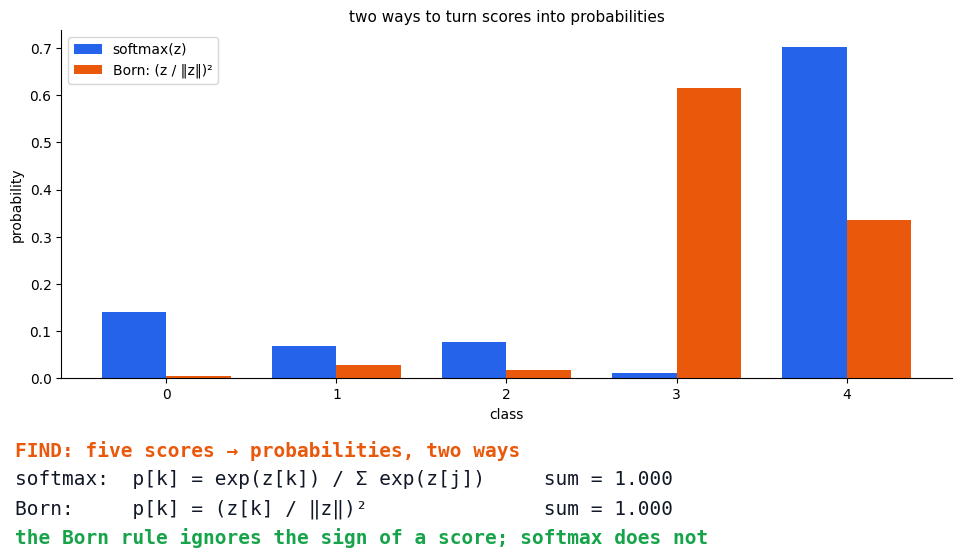

In [13]:
rng = np.random.default_rng(2)
z = rng.normal(size=5)                                  # five scores ("logits")
softmax = np.exp(z) / np.exp(z).sum()
born = normalize(z) ** 2                                # L2-normalize -> a valid state; square -> Born rule
print("scores  z :", z)
print("softmax   :", softmax, "   sum =", round(softmax.sum(), 6))
print("born      :", born, "   sum =", round(born.sum(), 6))
k = int(np.argmax(abs(z)))                              # the score with the largest absolute value
z2 = z.copy()
z2[k] = -z2[k]                                          # flip its sign
print(f"flip the sign of z[{k}]:  softmax p[{k}] {softmax[k]:.3f} -> {np.exp(z2[k]) / np.exp(z2).sum():.3f}     Born p[{k}] {born[k]:.3f} -> {normalize(z2)[k] ** 2:.3f}  (unchanged)")
print("largest score:", int(np.argmax(z)), "   largest absolute score:", k, "   -> softmax and Born pick different classes")

fig, ax = plt.subplots(figsize=(7.4, 4.2))
w, idx = 0.38, np.arange(5)
ax.bar(idx - w / 2, softmax, w, color=BLUE, label="softmax(z)")
ax.bar(idx + w / 2, born, w, color=ORANGE, label="Born: (z / ‖z‖)²")
ax.set_xlabel("class")
ax.set_ylabel("probability")
ax.set_xticks(idx)
ax.legend()
ax.set_title("two ways to turn scores into probabilities", fontsize=11)
show_steps("FIND: five scores → probabilities, two ways", [
    f"softmax:  p[k] = exp(z[k]) / Σ exp(z[j])     sum = {softmax.sum():.3f}",
    f"Born:     p[k] = (z[k] / ‖z‖)²               sum = {born.sum():.3f}",
    f"the Born rule ignores the sign of a score; softmax does not"])

plt.show()

**R — Result.** Both rules give a valid probability distribution (sum 1). They rank the classes differently: softmax rewards the largest *score*, the Born rule the largest *absolute* score, because squaring forgets the sign.

<span style="color:#dc2626">**Normalizing an embedding gives a valid quantum state, and squaring its entries is a measurement.**</span> That is how a quantum model reads out probabilities (`pₖ = |ψₖ|²`).

### 2.11 Preview: from a vector to a space

> A first look. Notebooks 3 (vector spaces) and 5 (Hilbert spaces) develop this in depth.

**S — Situation.** So far we had one vector. A quantum computer needs the whole **collection** of possible states, and ML has a close cousin: the **feature space** of the kernel trick.

**T — Task.** Say which collection a state lives in, how big it is, and how many real numbers a state really has.

**A — Action.**

- A **complex vector space** is the collection of all complex vectors of a given size, **closed** under the two operations of 2.2 and 2.3: add any two vectors, scale by any complex number, and you stay inside. Adding two states with complex weights is a **superposition** `α|0⟩ + β|1⟩`: "superposition" is just "linear combination in a complex vector space".
- A **Hilbert space** `ℋ` is a complex vector space that also has an **inner product** (2.6) and **completeness** (no "holes"; automatic in finite dimensions). So for qubits: <span style="color:#dc2626">**Hilbert space = `ℂⁿ` with the inner product `Σ conj(uₖ)·vₖ`.**</span>
- **Dimension** = the number of vectors in a basis. `ℂⁿ` has **complex dimension `n`** (equivalently `2n` real numbers).

| System | Hilbert space | Dimension |
|---|---|---|
| 1 qubit | $\mathbb{C}^2$ | 2 |
| 2 qubits | $\mathbb{C}^4$ | 4 |
| $n$ qubits | $\mathbb{C}^{2^n}$ | $2^n$ |

**Counting the real numbers of a state.** An `n`-component complex vector has `2n` real numbers. A *physical state* is a unit vector (**−1** for normalization) defined up to a global phase (**−1**). That leaves `2n − 2` real parameters:

| System | Complex dim $n$ | Real parameters of a state |
|---|---|---|
| 1 qubit | 2 | $2\cdot2-2=2$  → the two angles of the **Bloch sphere** |
| 2 qubits | 4 | $2\cdot4-2=6$ |
| $k$ qubits | $2^k$ | $2^{k+1}-2$ |

| Vector-space property | Statement |
|---|---|
| Closure | $u+v\in\mathcal{H}$ and $c\,v\in\mathcal{H}$ for every complex $c$ |
| Zero and inverses | $0\in\mathcal{H}$; every $v$ has $-v$ |
| Linearity | $c(u+v)=cu+cv$, $(c+d)v=cv+dv$, $c(dv)=(cd)v$ |
| Linear independence | no vector is a combination of the others |
| Subspace | a subset closed under the two operations, e.g. $\mathrm{span}\{\lvert00\rangle,\lvert11\rangle\}$ |

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: how many real numbers describe the state of **one qubit**, and what does that space look like? First check closure and dimension in numbers, then draw the space.

</div>

In [14]:
rng = np.random.default_rng(3)
u = rng.normal(size=4) + 1j * rng.normal(size=4)
v = rng.normal(size=4) + 1j * rng.normal(size=4)
a, b = 0.3 + 0.4j, -0.2 + 0.9j

w = a * u + b * v                                   # closure: a superposition is still a vector in C^4
print("closure OK: a*u + b*v has", w.shape[0], "components, like u and v")

# dimension = number of linearly independent vectors = matrix rank
print("rank of 4 random vectors in C^4 :", np.linalg.matrix_rank(np.column_stack([u, v, rng.normal(size=4) + 0j, rng.normal(size=4) * 1j])))
print("rank of {u, v, 2u+3v}            :", np.linalg.matrix_rank(np.column_stack([u, v, 2 * u + 3 * v])), "  (the third vector is dependent: the span has dimension 2)")

# real parameters of a quantum state of dimension n
for k in (1, 2, 3):
    n_ = 2 ** k
    print(f"{k} qubit(s): C^{n_} -> {2 * n_} real numbers - 1 (norm) - 1 (global phase) = {2 * n_ - 2}")

closure OK: a*u + b*v has 4 components, like u and v
rank of 4 random vectors in C^4 : 4
rank of {u, v, 2u+3v}            : 2   (the third vector is dependent: the span has dimension 2)
1 qubit(s): C^2 -> 4 real numbers - 1 (norm) - 1 (global phase) = 2
2 qubit(s): C^4 -> 8 real numbers - 1 (norm) - 1 (global phase) = 6
3 qubit(s): C^8 -> 16 real numbers - 1 (norm) - 1 (global phase) = 14


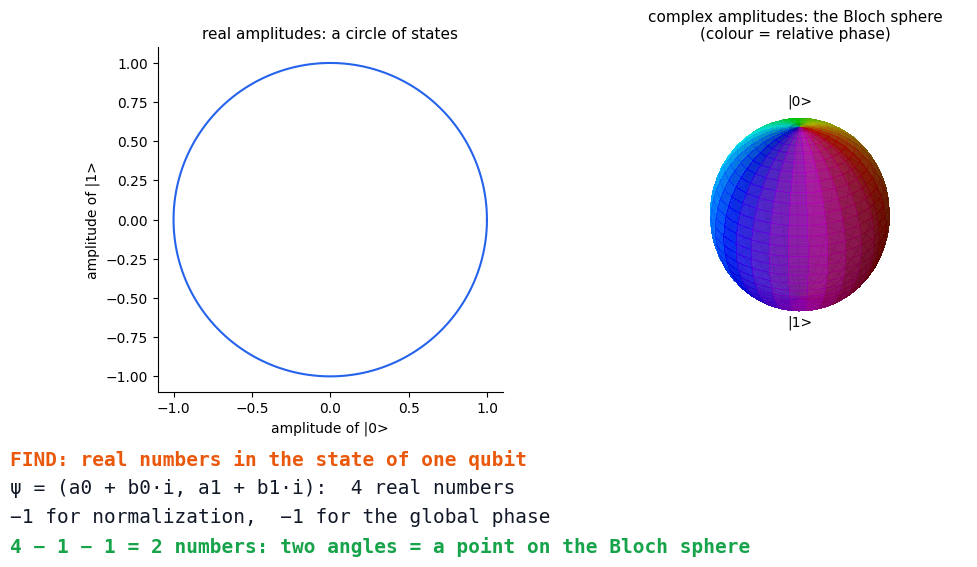

In [15]:
fig = plt.figure(figsize=(11, 4.8))

# real amplitudes only: the unit circle of states (cos t, sin t)
ax = fig.add_subplot(1, 2, 1)
t = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(t), np.sin(t), color=BLUE)
ax.set_aspect("equal")
ax.set_xlabel("amplitude of |0>")
ax.set_ylabel("amplitude of |1>")
ax.set_title("real amplitudes: a circle of states", fontsize=11)

# complex amplitudes: the Bloch sphere, state (cos(th/2), e^{i ph} sin(th/2)) -> point on the sphere
ax = fig.add_subplot(1, 2, 2, projection="3d")
th, ph = np.meshgrid(np.linspace(0, np.pi, 30), np.linspace(0, 2 * np.pi, 60))
X, Y, Z = np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)
ax.plot_surface(X, Y, Z, facecolors=plt.cm.hsv(ph / (2 * np.pi)), alpha=0.8, linewidth=0, antialiased=False)
ax.text(0, 0, 1.25, "|0>", ha="center")
ax.text(0, 0, -1.35, "|1>", ha="center")
ax.set_box_aspect((1, 1, 1))
ax.set_axis_off()
ax.set_title("complex amplitudes: the Bloch sphere\n(colour = relative phase)", fontsize=11)
show_steps("FIND: real numbers in the state of one qubit", [
    "ψ = (a0 + b0·i, a1 + b1·i):  4 real numbers",
    "−1 for normalization,  −1 for the global phase",
    "4 − 1 − 1 = 2 numbers: two angles = a point on the Bloch sphere"], tight=False)

plt.show()

#### ML view: a Hilbert space is a *feature space*

You have already used Hilbert spaces: the **kernel trick**. A feature map `φ: 𝒳 → ℋ` sends data into a Hilbert space, and a kernel is the inner product there: `k(x, y) = ⟨φ(x), φ(y)⟩`. Quantum machine learning does the same, with one twist: **`φ(x)` is a quantum state**, a unit vector in `ℂ^(2ⁿ)` prepared by a circuit. Below: the classical polynomial kernel computed two ways (explicit features vs. kernel), then a tiny **quantum-style feature map** `x ↦ (cos x, sin x)` whose kernel is `cos²(x − y)`.

In [16]:
# 1) Classical: the polynomial kernel k(x, y) = (x·y)^2 equals an inner product in a bigger space
def phi_poly(x):                       # for x in R^2 : (x1², √2 x1x2, x2²)
    return np.array([x[0] ** 2, np.sqrt(2) * x[0] * x[1], x[1] ** 2])


x, y = np.array([1.0, 2.0]), np.array([3.0, -0.5])
print("kernel            :", (x @ y) ** 2)
print("<phi(x), phi(y)>  :", round(phi_poly(x) @ phi_poly(y), 10), "   (the same number, computed in 3 dimensions)")

kernel            : 4.0
<phi(x), phi(y)>  : 4.0    (the same number, computed in 3 dimensions)


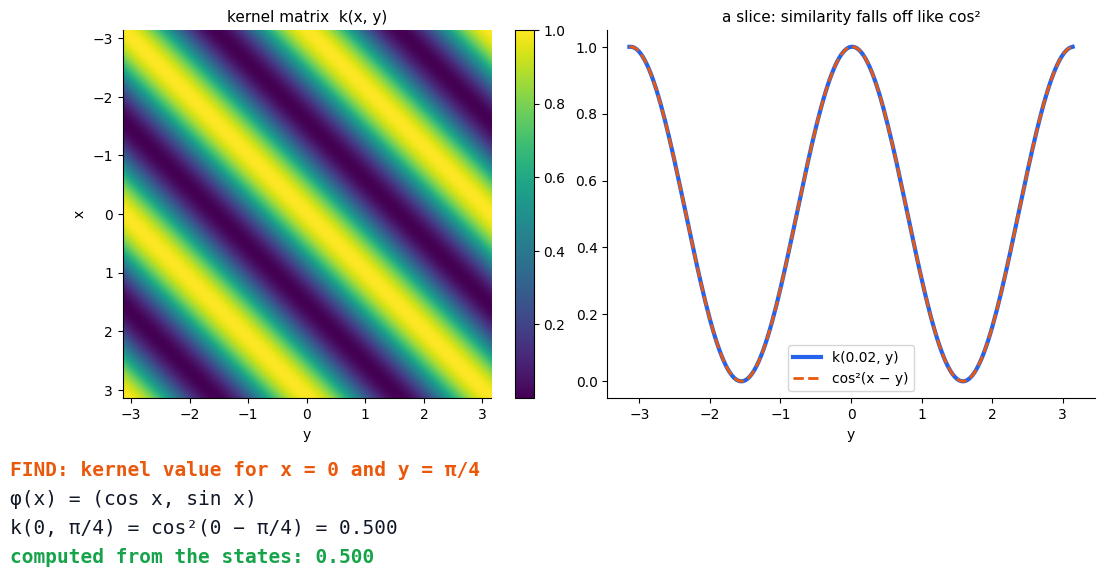

In [17]:
# 2) Quantum-style feature map: x -> unit vector (cos x, sin x)   (this is "angle encoding")
def phi_quantum(x):
    return np.array([np.cos(x), np.sin(x)], dtype=complex)


def quantum_kernel(x, y):
    return abs(np.vdot(phi_quantum(x), phi_quantum(y))) ** 2          # abs(<phi(x)|phi(y)>)**2


xs = np.linspace(-np.pi, np.pi, 200)
K = np.array([[quantum_kernel(p, q) for q in xs] for p in xs])

fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
im = axs[0].imshow(K, extent=[-np.pi, np.pi, np.pi, -np.pi], cmap="viridis")
axs[0].set_title("kernel matrix  k(x, y)", fontsize=11)
axs[0].set_xlabel("y")
axs[0].set_ylabel("x")
i0 = 100                                                    # slice at x = xs[i0]
axs[1].plot(xs, K[i0], color=BLUE, lw=3, label=f"k({xs[i0]:.2f}, y)")
axs[1].plot(xs, np.cos(xs - xs[i0]) ** 2, "--", color=ORANGE, lw=2, label="cos²(x − y)")
axs[1].set_title("a slice: similarity falls off like cos²", fontsize=11)
axs[1].set_xlabel("y")
axs[1].legend(loc="lower center")
d = np.pi / 4
show_steps("FIND: kernel value for x = 0 and y = π/4", [
    "φ(x) = (cos x, sin x)",
    f"k(0, π/4) = cos²(0 − π/4) = {np.cos(d) ** 2:.3f}",
    f"computed from the states: {quantum_kernel(0, d):.3f}"])
plt.colorbar(im, ax=axs[0])                                 # after show_steps, so the layout engine is already set

plt.show()

**R — Result.** One qubit lives in `ℂ²` and needs only **2 real parameters** (the Bloch sphere); `k` qubits live in `ℂ^(2ᵏ)` and need `2^(k+1) − 2`. The state space grows exponentially, and a quantum feature map reaches it with a circuit.

<span style="color:#dc2626">**The state of a quantum system *is* a unit vector in a Hilbert space.**</span> Gates, measurement and entanglement are all statements about this space.

### 2.12 Preview: basis and change of basis

> A first look. Notebooks 3 (basis, dimension) and 4 (orthonormal bases) develop this in depth.

**S — Situation.** You can describe the same arrow with different axes. "Measure in the computational basis" and "measure in the Hadamard basis" are two different sets of axes for the same qubit, and PCA in ML does the same thing to your data.

**T — Task.** Write a state in a new orthonormal basis and read off the new probabilities.

**A — Action.** **Dirac (bra–ket) notation** is compact linear algebra:

| Notation | Meaning | numpy |
|---|---|---|
| $\lvert v\rangle$ ("ket") | column vector | `v` |
| $\langle v\rvert$ ("bra") | conjugate transpose (row) | `v.conj()` |
| $\langle u\vert v\rangle$ | inner product (a number) | `np.vdot(u, v)` |
| $\lvert u\rangle\langle v\rvert$ | outer product (a matrix) | `np.outer(u, v.conj())` |

An **orthonormal basis** $\{|e_i\rangle\}$ satisfies $\langle e_i|e_j\rangle=\delta_{ij}$ (length 1, mutually orthogonal). Any state expands as

$$|\psi\rangle = \sum_i c_i |e_i\rangle, \qquad c_i = \langle e_i|\psi\rangle, \qquad \sum_i |c_i|^2 = 1$$

- `cᵢ` — the **coordinate** of `ψ` along `eᵢ`: an inner product (2.6); `|cᵢ|²` is the probability of finding `eᵢ`
- the projectors `|eᵢ⟩⟨eᵢ|` add up to the identity (**completeness**)

Stack the basis as the **columns** of a matrix `B = [e₁ e₂ …]`. Then <span style="color:#dc2626">**`c = B†ψ` (new coordinates) and `ψ = B c` (back).**</span> `B` is **unitary**, so the change of basis keeps lengths. For the Hadamard basis `|±⟩ = (|0⟩ ± |1⟩)/√2`, `B` is the **Hadamard matrix**. If the basis is not orthonormal you need `B⁻¹` instead of `B†`.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take `|+⟩ = (1, 1)/√2`. What are its coordinates in the computational basis `{|0⟩, |1⟩}` and in the Hadamard basis `{|+⟩, |−⟩}`?

</div>

In [18]:
Z_basis, X_basis = [ket0, ket1], [plus, minus]


def coefficients(psi, basis):
    """Coordinates c_i = <e_i|psi> of a state in an orthonormal basis."""
    return np.array([np.vdot(e, psi) for e in basis])


# completeness: the projectors |e><e| of an orthonormal basis add up to the identity
print("sum of projectors, Z basis:\n", clean(sum(np.outer(e, e.conj()) for e in Z_basis)).real)
print("sum of projectors, X basis:\n", clean(sum(np.outer(e, e.conj()) for e in X_basis)).real)

# change of basis as a matrix: columns = the new basis vectors
B = np.column_stack(X_basis)
psi = np.array([3 / 5, 4j / 5])
c = B.conj().T @ psi                                  # coordinates in the X basis
print("\nB == Hadamard matrix :", np.allclose(B, Hg))
print("B unitary            :", np.allclose(B.conj().T @ B, np.eye(2)))
print("coordinates c        :", c, "   sum |c|^2 =", round(np.sum(abs(c) ** 2), 10))
print("matches coefficients():", np.allclose(c, coefficients(psi, X_basis)))
print("round trip  B c == psi:", np.allclose(B @ c, psi))

sum of projectors, Z basis:
 [[1. 0.]
 [0. 1.]]
sum of projectors, X basis:
 [[1. 0.]
 [0. 1.]]

B == Hadamard matrix : True
B unitary            : True
coordinates c        : [0.424+0.566j 0.424-0.566j]    sum |c|^2 = 1.0
matches coefficients(): True
round trip  B c == psi: True


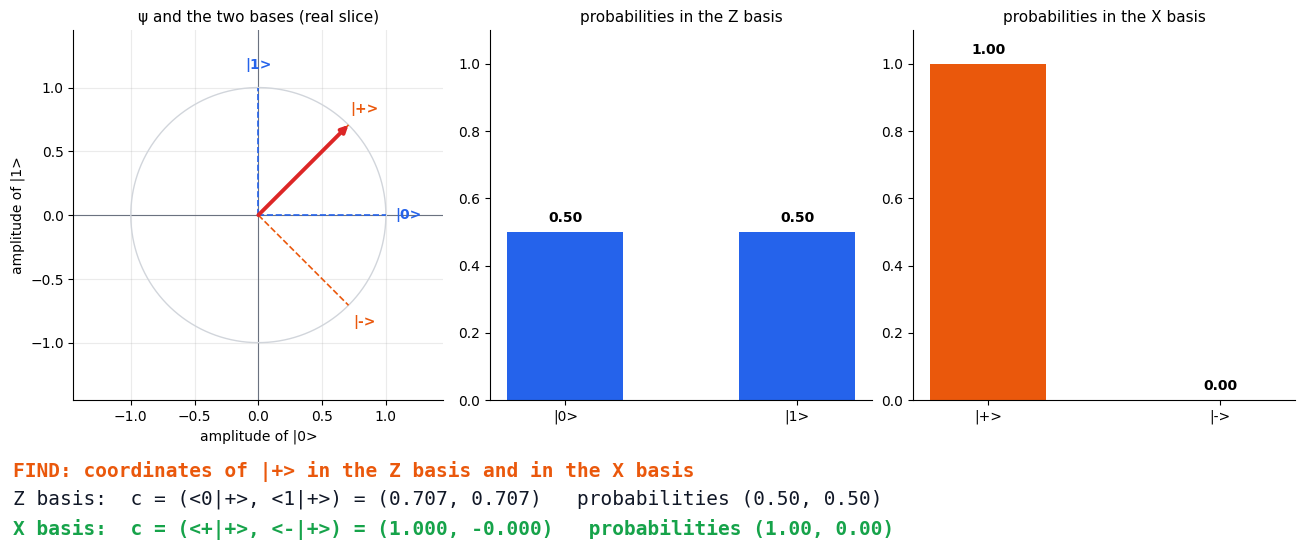

In [19]:
psi = plus                                         # try: ket0, minus, or any normalized vector
cz, cx = coefficients(psi, Z_basis), coefficients(psi, X_basis)
pz, px = abs(cz) ** 2, abs(cx) ** 2

fig, axs = plt.subplots(1, 3, figsize=(13, 4.4))
ax = new_plane(lim=1.45, title="ψ and the two bases (real slice)", ax=axs[0], unit_circle=True)
for e, col, lab in [(ket0, BLUE, "|0>"), (ket1, BLUE, "|1>"), (plus, ORANGE, "|+>"), (minus, ORANGE, "|->")]:
    ax.plot([0, e[0].real], [0, e[1].real], color=col, lw=1.2, ls="--")
    ax.text(e[0].real * 1.18, e[1].real * 1.18, lab, color=col, ha="center", va="center", fontweight="bold")
draw_arrow(ax, psi[0].real + 1j * psi[1].real, RED, lw=2.8)
ax.set_xlabel("amplitude of |0>")
ax.set_ylabel("amplitude of |1>")
axs[1].bar(["|0>", "|1>"], pz, color=BLUE, width=0.5)
axs[1].set_ylim(0, 1.1)
axs[1].set_title("probabilities in the Z basis", fontsize=11)
axs[2].bar(["|+>", "|->"], px, color=ORANGE, width=0.5)
axs[2].set_ylim(0, 1.1)
axs[2].set_title("probabilities in the X basis", fontsize=11)
for ax, vals in ((axs[1], pz), (axs[2], px)):
    for k, val in enumerate(vals):
        ax.text(k, val + 0.03, f"{val:.2f}", ha="center", fontweight="bold")
show_steps("FIND: coordinates of |+> in the Z basis and in the X basis", [
    f"Z basis:  c = (<0|+>, <1|+>) = ({cz[0].real:.3f}, {cz[1].real:.3f})   probabilities ({pz[0]:.2f}, {pz[1]:.2f})",
    f"X basis:  c = (<+|+>, <-|+>) = ({cx[0].real:.3f}, {cx[1].real:.3f})   probabilities ({px[0]:.2f}, {px[1]:.2f})"])

plt.show()

#### ML view: coefficients are PCA-style coordinates

Computing `cᵢ = ⟨eᵢ|ψ⟩` is exactly projecting a vector onto an orthonormal basis, as in **PCA**: the principal components form an orthonormal basis, and the "scores" are inner products with them. Changing the measurement basis in QML is the same as choosing different principal axes: the vector is unchanged, only its coordinates are.

In [20]:
rng = np.random.default_rng(4)
X = rng.normal(size=(500, 2)) @ np.array([[2.0, 0.5], [0.0, 0.6]])
X = X - X.mean(0)
_, _, Vt = np.linalg.svd(X, full_matrices=False)        # rows of Vt: an orthonormal basis (the principal axes)

x0 = X[0] / np.linalg.norm(X[0])                         # one sample, as a unit vector
scores_pca = Vt @ x0                                     # coordinates c_i = <e_i|x> in the PCA basis
scores_std = np.eye(2) @ x0                              # coordinates in the standard basis

print("sum of c_i² (PCA basis)      :", round(np.sum(scores_pca ** 2), 10))
print("sum of c_i² (standard basis) :", round(np.sum(scores_std ** 2), 10))
print("same vector, different coordinates:", scores_std, "vs", scores_pca)

sum of c_i² (PCA basis)      : 1.0
sum of c_i² (standard basis) : 1.0
same vector, different coordinates: [-0.946 -0.323] vs [-0.997  0.073]


**R — Result.** For `|+⟩` the Z-basis coordinates are `(0.707, 0.707)`, which means a 50/50 outcome, and the X-basis coordinates are `(1, 0)`, which means a certain outcome. **Same state, different axes.** The squared coordinates add up to 1 in every orthonormal basis.

<span style="color:#dc2626">**Rotating the axes by 45° turns "50/50" into "100/0".**</span> That is what the Hadamard gate does, and why it turns "Z-basis questions" into "X-basis questions".

### 2.13 Preview: linear maps, matrices acting on vectors

> A first look. Notebook 3 develops linear combinations and maps in depth.

**S — Situation.** A quantum gate and a dense layer of a neural network are the same kind of object: a **matrix acting on a vector**.

**T — Task.** Read what a matrix does from its columns, and predict what happens when you apply two of them in a row.

**A — Action.** A map `A: ℂⁿ → ℂᵐ` is **linear** if

$$A(\alpha u+\beta v)=\alpha\,Au+\beta\,Av.$$

Every linear map is a **matrix**, and the matrix is read off from what it does to the basis vectors: <span style="color:#dc2626">**column `j` of `A` is `A·eⱼ`.**</span> Applying it is the matrix–vector product `(Aψ)ᵢ = Σⱼ Aᵢⱼ ψⱼ`.

- **Superposition principle.** Quantum evolution is linear: a gate acts on every branch of a superposition separately.
- **Composition is multiplication, and order matters.** "First `A`, then `B`" is `BA`, and `AB ≠ BA` in general (for instance `XZ = −ZX`).
- **Matrix elements:** `Aᵢⱼ = ⟨eᵢ|A|eⱼ⟩`, and `A = Σ Aᵢⱼ |eᵢ⟩⟨eⱼ|` (outer products).
- The **adjoint** `A† = Āᵀ` (conjugate transpose) satisfies `⟨u|Av⟩ = ⟨A†u|v⟩`.

In Python: **`A @ psi`**, and `A.conj().T` for the adjoint.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: a real `2×2` matrix `A`. Where do the basis vectors `e₁`, `e₂` land, and what happens to the whole grid?

</div>

In [21]:
a, b = 0.3 + 0.4j, -0.2 + 0.9j
u2 = np.array([0.6, 0.8j])
v2 = np.array([1, 1j]) / np.sqrt(2)
print("linearity     :", np.allclose(Hg @ (a * u2 + b * v2), a * (Hg @ u2) + b * (Hg @ v2)))

print("column 0 of H :", Hg[:, 0], "= H|0> =", Hg @ ket0)
print("<0|H|1>       :", clean(np.vdot(ket0, Hg @ ket1), 4), "= H[0,1] =", clean(Hg[0, 1], 4))
print("X from outer products |0><1| + |1><0| :\n", (np.outer(ket0, ket1.conj()) + np.outer(ket1, ket0.conj())).real)

print("\nXZ == ZX  :", np.allclose(Xg @ Zg, Zg @ Xg))
print("XZ == -ZX :", np.allclose(Xg @ Zg, -Zg @ Xg))
print("adjoint rule <u|Mv> = <M†u|v> :", np.isclose(np.vdot(u2, (1j * Hg) @ v2), np.vdot((1j * Hg).conj().T @ u2, v2)))

linearity     : True
column 0 of H : [0.707+0.j 0.707+0.j] = H|0> = [0.707+0.j 0.707+0.j]
<0|H|1>       : (0.7071+0j) = H[0,1] = (0.7071+0j)
X from outer products |0><1| + |1><0| :
 [[0. 1.]
 [1. 0.]]

XZ == ZX  : False
XZ == -ZX : True
adjoint rule <u|Mv> = <M†u|v> : True


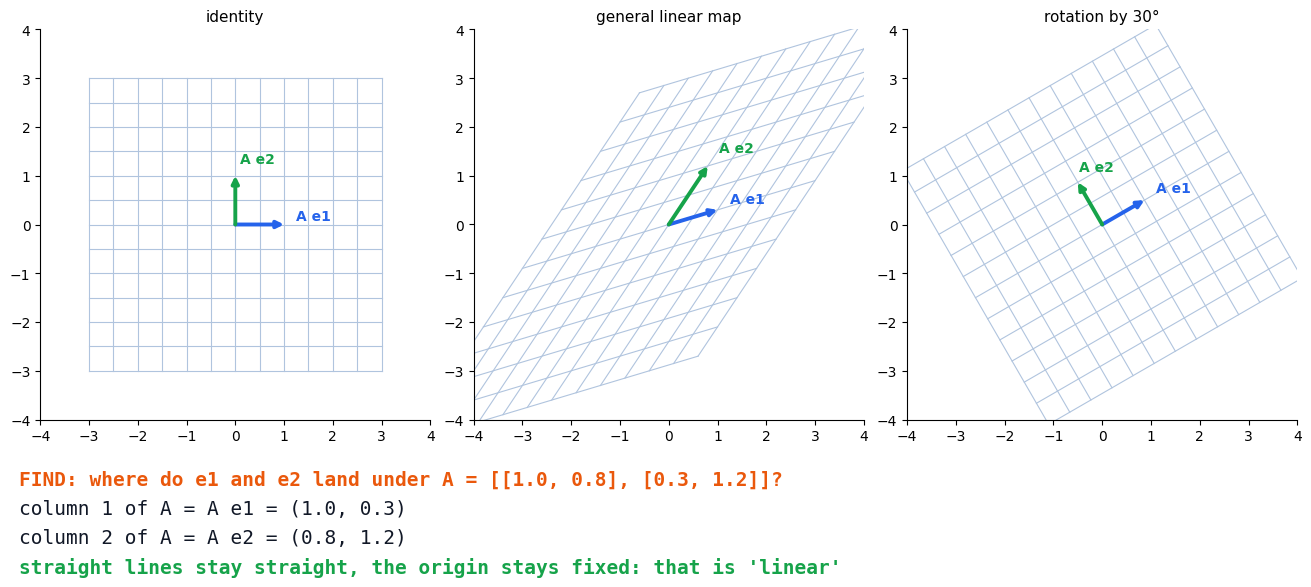

In [22]:
def draw_grid(ax, M, title):
    ks = np.linspace(-3, 3, 13)
    for k in ks:
        for line in (np.array([[k, k], [-3, 3]]), np.array([[-3, 3], [k, k]])):
            q = M @ line
            ax.plot(q[0], q[1], color="lightsteelblue", lw=0.8)
    for col, color, lab in ((M[:, 0], BLUE, "A e1"), (M[:, 1], GREEN, "A e2")):
        ax.annotate("", xy=col, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=color, lw=2.8, shrinkA=0, shrinkB=0))
        ax.text(col[0] * 1.15 + 0.1, col[1] * 1.15 + 0.1, lab, color=color, fontweight="bold")
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=11)


ang = np.deg2rad(30)
A_gen = np.array([[1.0, 0.8], [0.3, 1.2]])
fig, axs = plt.subplots(1, 3, figsize=(13, 4.6))
draw_grid(axs[0], np.eye(2), "identity")
draw_grid(axs[1], A_gen, "general linear map")
draw_grid(axs[2], np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]]), "rotation by 30°")
show_steps("FIND: where do e1 and e2 land under A = [[1.0, 0.8], [0.3, 1.2]]?", [
    "column 1 of A = A e1 = (1.0, 0.3)",
    "column 2 of A = A e2 = (0.8, 1.2)",
    "straight lines stay straight, the origin stays fixed: that is 'linear'"])

plt.show()

#### ML view: a stack of linear layers is one matrix

A dense layer without activation is a linear map `y = Wx`; the columns of `W` are the images of the input features. Two such layers collapse into **one** matrix `W₂W₁`, which is why you need nonlinearities. A quantum circuit is the same: ten gates multiply into **one** unitary. The only nonlinearity in a quantum model enters through **measurement** (squaring the amplitudes) and through how the data is encoded.

In [23]:
rng = np.random.default_rng(5)
W1, W2 = rng.normal(size=(4, 3)), rng.normal(size=(2, 4))
x = rng.normal(size=3)
print("two linear layers == one matrix W2@W1 :", np.allclose(W2 @ (W1 @ x), (W2 @ W1) @ x))

U = Hg @ Zg @ Hg @ Xg @ Hg                         # five gates -> one 2x2 matrix
step = Hg @ (Xg @ (Hg @ (Zg @ (Hg @ ket0))))
print("circuit collapses to a single matrix  :", np.allclose(U @ ket0, step), "\n", U.real)

out = U @ ket0
print("\ndoubling the input state: amplitudes x2, probabilities x4 ->", abs(2 * out) ** 2 / abs(out) ** 2)

two linear layers == one matrix W2@W1 : True
circuit collapses to a single matrix  : True 
 [[ 0.707  0.707]
 [ 0.707 -0.707]]

doubling the input state: amplitudes x2, probabilities x4 -> [4. 4.]


**R — Result.** The columns of `A` are `(1.0, 0.3)` and `(0.8, 1.2)`: they say where `e₁` and `e₂` land, and so where **everything** lands. Two matrices applied in a row are one matrix, and the order matters (`XZ = −ZX`).

<span style="color:#dc2626">**A linear map is fully described by what it does to the basis vectors.**</span> A circuit of any length is one matrix.

### 2.14 Preview: eigenvalues and eigenvectors

> A first look. Notebooks 4 and 5 and the notebooks on gates and measurement develop this in depth.

**S — Situation.** Most vectors change direction when a matrix acts on them. A few special directions do not. Those directions are the **possible outcomes of a measurement**, and in ML they are the **principal axes** of PCA.

**T — Task.** Find the directions a matrix only stretches, and the factors it stretches them by.

**A — Action.** The **eigenvalue equation**:

$$A\,|v\rangle=\lambda\,|v\rangle,\qquad |v\rangle\neq0$$

- `|v⟩` — an **eigenvector**: a direction that `A` only stretches
- `λ` (lambda) — the **eigenvalue**, a complex number: the stretch factor (a negative or complex `λ` flips or phase-rotates the vector)
- they are found from `det(A − λI) = 0`

**What eigenvalues mean in quantum computing.**

- **Hermitian matrices (`H† = H`) are observables.** Their eigenvalues are **real**, eigenvectors for different eigenvalues are **orthogonal** and form an orthonormal basis. *Spectral decomposition:* `O = Σ λₖ |vₖ⟩⟨vₖ|`. *Measuring `O`* returns an eigenvalue `λₖ` with probability `|⟨vₖ|ψ⟩|²` and leaves the state in `|vₖ⟩`; the average is `⟨O⟩ = Σ λₖ pₖ = ⟨ψ|O|ψ⟩`.
- **Unitary matrices are gates.** Their eigenvalues have modulus 1, `λ = e^{iφ}`: the gate only applies a **phase** to its eigenvectors.

| Matrix | Eigenvalues | Eigenvectors |
|---|---|---|
| $Z$ | $+1,\,-1$ | $\lvert0\rangle,\,\lvert1\rangle$ (computational basis) |
| $X$ | $+1,\,-1$ | $\lvert+\rangle,\,\lvert-\rangle$ (Hadamard basis) |
| $Y$ | $+1,\,-1$ | $\lvert{+i}\rangle,\,\lvert{-i}\rangle$ |
| $S=\mathrm{diag}(1,i)$ | $1,\,i$ | $\lvert0\rangle,\,\lvert1\rangle$ |
| $R_Z(\theta)$ | $e^{-i\theta/2},\,e^{+i\theta/2}$ | $\lvert0\rangle,\,\lvert1\rangle$ |

So "measure in the computational basis" means "measure `Z`", and "measure in the Hadamard basis" means "measure `X`": the bases of 2.12 are the eigenbases of these observables.

In Python: **`np.linalg.eigh(A)`** for Hermitian matrices (real eigenvalues, orthonormal eigenvectors) and `np.linalg.eigvals(A)` for general ones.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take the symmetric matrix `A = [[2, 1], [1, 2]]`. Which directions does it only stretch, and by how much? Then measure the observable `X` on a state.

</div>

In [24]:
# Hermitian observables: real eigenvalues, A v = lambda v
for name, M in {"Z": Zg, "X": Xg, "Y": Yg}.items():
    vals, vecs = np.linalg.eigh(M)
    ok = all(np.allclose(M @ vecs[:, k], vals[k] * vecs[:, k]) for k in range(2))
    print(f"{name}: eigenvalues {vals}   A v = lambda v for all: {ok}   eigenvectors orthonormal: {np.allclose(vecs.conj().T @ vecs, np.eye(2))}")

# spectral decomposition and the measurement statistics of X on a state
vals, vecs = np.linalg.eigh(Xg)
rebuilt = sum(l * np.outer(vecs[:, k], vecs[:, k].conj()) for k, l in enumerate(vals))
print("\nX = sum lambda |v><v| :", np.allclose(rebuilt, Xg))

psi = np.array([3 / 5, 4 / 5], dtype=complex)
p = abs(vecs.conj().T @ psi) ** 2
print("measuring X on psi -> outcomes", vals, "with probabilities", p)
print("<X> = sum lambda p    :", round(np.sum(vals * p), 6), "   <psi|X|psi> =", round(np.vdot(psi, Xg @ psi).real, 6))

# unitary: eigenvalues on the unit circle
rng = np.random.default_rng(6)
Q, _ = np.linalg.qr(rng.normal(size=(3, 3)) + 1j * rng.normal(size=(3, 3)))
print()
for name, U_ in {"H": Hg, "S": Sg, "RZ(0.7)": rz(0.7), "random 3x3 unitary": Q}.items():
    ev = np.linalg.eigvals(U_)
    print(f"{name:20s} eigenvalues {np.round(ev, 3)}   |lambda| = {np.round(abs(ev), 6)}")

Z: eigenvalues [-1.  1.]   A v = lambda v for all: True   eigenvectors orthonormal: True
X: eigenvalues [-1.  1.]   A v = lambda v for all: True   eigenvectors orthonormal: True
Y: eigenvalues [-1.  1.]   A v = lambda v for all: True   eigenvectors orthonormal: True

X = sum lambda |v><v| : True
measuring X on psi -> outcomes [-1.  1.] with probabilities [0.02 0.98]
<X> = sum lambda p    : 0.96    <psi|X|psi> = 0.96

H                    eigenvalues [ 1.+0.j -1.+0.j]   |lambda| = [1. 1.]
S                    eigenvalues [1.+0.j 0.+1.j]   |lambda| = [1. 1.]
RZ(0.7)              eigenvalues [0.939-0.343j 0.939+0.343j]   |lambda| = [1. 1.]
random 3x3 unitary   eigenvalues [-0.975+0.223j  0.208-0.978j -0.716-0.698j]   |lambda| = [1. 1. 1.]


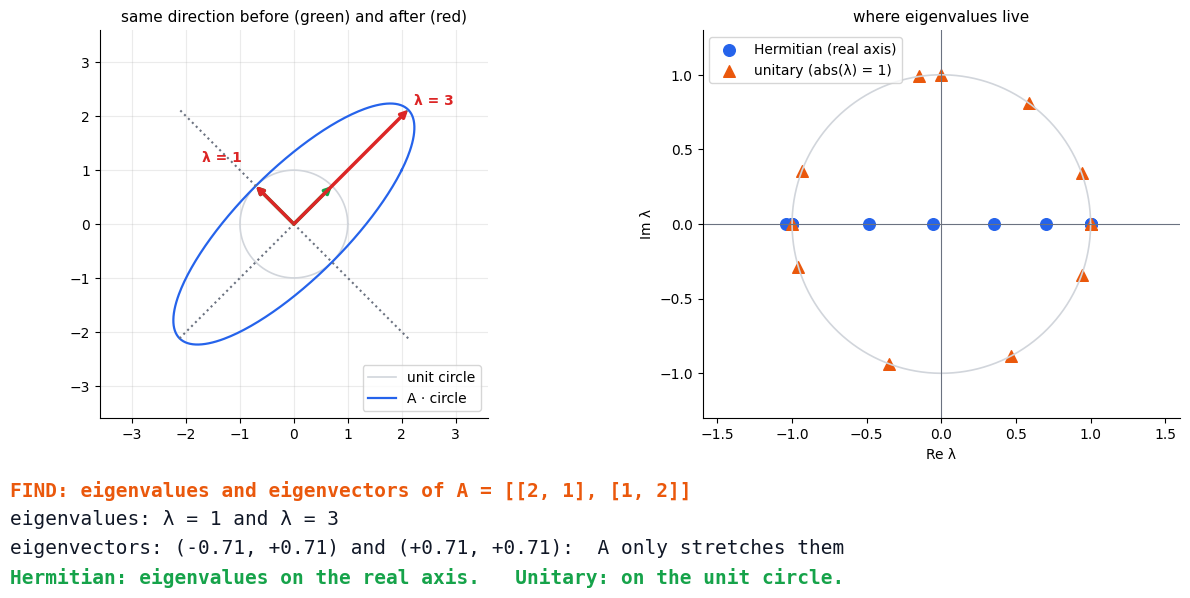

In [25]:
rng = np.random.default_rng(7)
fig, axs = plt.subplots(1, 2, figsize=(12.4, 5.2))

# --- left: the ellipse and the eigen-axes of a symmetric matrix
A = np.array([[2.0, 1.0], [1.0, 2.0]])
lam, V = np.linalg.eigh(A)
t = np.linspace(0, 2 * np.pi, 300)
P = np.vstack([np.cos(t), np.sin(t)])
E = A @ P
ax = axs[0]
ax.plot(P[0], P[1], color="#d1d5db", lw=1.2, label="unit circle")
ax.plot(E[0], E[1], color=BLUE, lw=1.6, label="A · circle")
for k in range(2):
    v = V[:, k]
    ax.plot([-3 * v[0], 3 * v[0]], [-3 * v[1], 3 * v[1]], ":", color=GRAY)
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=GREEN, lw=2.5, shrinkA=0, shrinkB=0))
    ax.annotate("", xy=lam[k] * v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=RED, lw=2.5, shrinkA=0, shrinkB=0))
    dx, dy, ha = ((-0.25, 0.45, "right") if k == 0 else (0.1, 0.1, "left"))        # keep the labels off the ellipse
    ax.text(lam[k] * v[0] + dx, lam[k] * v[1] + dy, f"λ = {lam[k]:.0f}", color=RED, fontweight="bold", ha=ha)
ax.set_aspect("equal")
ax.set_xlim(-3.6, 3.6)
ax.set_ylim(-3.6, 3.6)
ax.grid(alpha=0.25)
ax.legend(loc="lower right")
ax.set_title("same direction before (green) and after (red)", fontsize=11)

# --- right: where eigenvalues live in the complex plane
ax = axs[1]
ax.plot(np.cos(t), np.sin(t), color="#d1d5db", lw=1.2)
ax.axhline(0, color=GRAY, lw=0.8)
ax.axvline(0, color=GRAY, lw=0.8)
Ah = rng.normal(size=(5, 5)) + 1j * rng.normal(size=(5, 5))
Ah = (Ah + Ah.conj().T) / 2
Q6, _ = np.linalg.qr(rng.normal(size=(6, 6)) + 1j * rng.normal(size=(6, 6)))
herm = np.concatenate([np.linalg.eigvalsh(M) for M in (Zg, Xg, Yg)] + [np.linalg.eigvalsh(Ah) / 3]).astype(complex)
unit = np.concatenate([np.linalg.eigvals(M) for M in (Hg, Sg, rz(0.7), Q6)])
ax.scatter(herm.real, herm.imag, s=70, marker="o", color=BLUE, label="Hermitian (real axis)")
ax.scatter(unit.real, unit.imag, s=70, marker="^", color=ORANGE, label="unitary (abs(λ) = 1)")
ax.set_aspect("equal")
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.3, 1.3)
ax.legend(loc="upper left")
ax.set_xlabel("Re λ")
ax.set_ylabel("Im λ")
ax.set_title("where eigenvalues live", fontsize=11)
show_steps("FIND: eigenvalues and eigenvectors of A = [[2, 1], [1, 2]]", [
    f"eigenvalues: λ = {lam[0]:.0f} and λ = {lam[1]:.0f}",
    f"eigenvectors: ({V[0, 0]:+.2f}, {V[1, 0]:+.2f}) and ({V[0, 1]:+.2f}, {V[1, 1]:+.2f}):  A only stretches them",
    "Hermitian: eigenvalues on the real axis.   Unitary: on the unit circle."])

plt.show()

#### ML view: PCA is an eigendecomposition

The covariance matrix `C` is Hermitian (real symmetric). Its eigenvectors are the **principal axes** and its eigenvalues are the **variances** along them: the same spectral decomposition `C = Σ λₖ|vₖ⟩⟨vₖ|` as an observable, with "outcome probability" replaced by "share of variance". When the matrix is too big to diagonalize, **power iteration** (repeated multiplication and normalization, as in PageRank) converges to the top eigenvector.

eigenvalue 4.781   variance of the data along its eigenvector = 4.781
eigenvalue 0.304   variance of the data along its eigenvector = 0.304
power iteration vs top eigenvector, abs(cos) = 1.0


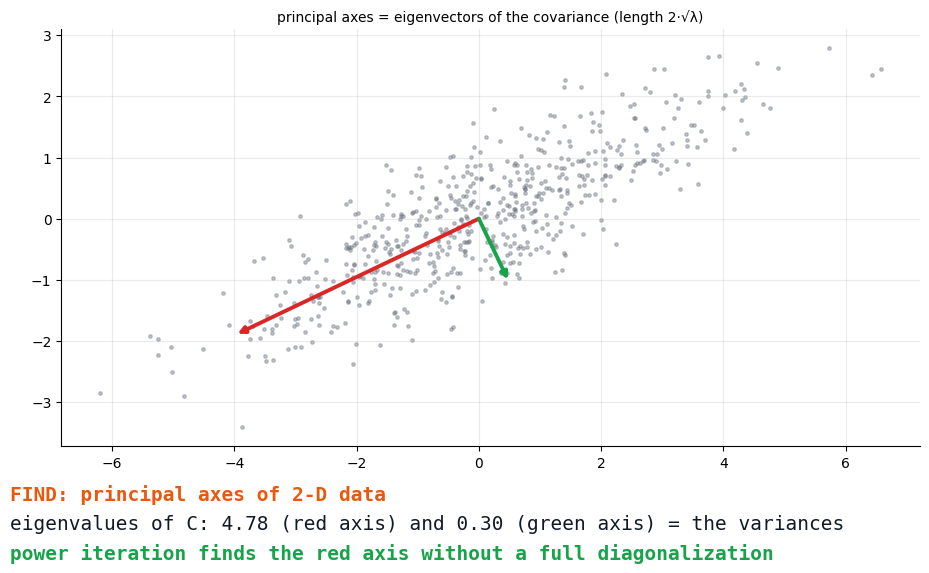

In [26]:
rng = np.random.default_rng(8)
Xd = rng.normal(size=(600, 2)) @ np.array([[2.0, 0.9], [0.0, 0.6]])
Xd = Xd - Xd.mean(0)
C = Xd.T @ Xd / len(Xd)
lam_c, V_c = np.linalg.eigh(C)                       # ascending order

for k in (1, 0):
    print(f"eigenvalue {lam_c[k]:.3f}   variance of the data along its eigenvector = {np.var(Xd @ V_c[:, k]):.3f}")

vec = rng.normal(size=2)
for _ in range(50):
    vec = C @ vec
    vec = vec / np.linalg.norm(vec)                  # power iteration
print("power iteration vs top eigenvector, abs(cos) =", round(abs(vec @ V_c[:, 1]), 6))

plt.figure(figsize=(5.8, 5.2))
plt.scatter(Xd[:, 0], Xd[:, 1], s=6, alpha=0.4, color=GRAY)
for k, col in [(1, RED), (0, GREEN)]:
    plt.annotate("", xy=2 * np.sqrt(lam_c[k]) * V_c[:, k], xytext=(0, 0),
                 arrowprops=dict(arrowstyle="-|>", color=col, lw=2.8, shrinkA=0, shrinkB=0))
plt.gca().set_aspect("equal")
plt.grid(alpha=0.25)
plt.title("principal axes = eigenvectors of the covariance (length 2·√λ)", fontsize=10)
show_steps("FIND: principal axes of 2-D data", [
    f"eigenvalues of C: {lam_c[1]:.2f} (red axis) and {lam_c[0]:.2f} (green axis) = the variances",
    "power iteration finds the red axis without a full diagonalization"])

plt.show()

**R — Result.** `A = [[2, 1], [1, 2]]` has eigenvalues `3` and `1`: along its two eigenvectors it only stretches (by 3 and by 1). Measuring `X` returns `+1` or `−1`, and the average `⟨X⟩ = Σ λₖ pₖ` equals `⟨ψ|X|ψ⟩`.

<span style="color:#dc2626">**Eigenvectors are the possible outcomes of a measurement, eigenvalues are the numbers you read off.**</span> Hermitian matrices give real outcomes, and unitary matrices (gates) only turn eigenvectors by a phase.

### 2.15 Preview: unitary and Hermitian matrices

> A first look. The notebooks on gates and measurement develop these in depth.

**S — Situation.** A quantum computer applies **gates** and reads **observables**. Mathematically a gate is a unitary matrix and an observable is a Hermitian matrix.

**T — Task.** Test whether a matrix is unitary or Hermitian, and see what a unitary does to a state.

**A — Action.** A **linear operator** is a matrix `A` acting on `|ψ⟩`. Its **adjoint** is `A† = Āᵀ` (conjugate transpose, 2.13).

| Type | Condition | Role in QML |
|---|---|---|
| **Unitary** | $U^\dagger U = I$ | quantum **gates**: the layers of a circuit |
| **Hermitian** | $H^\dagger = H$ | **observables**: real eigenvalues, the measurable quantities |

<span style="color:#dc2626">**Unitaries preserve inner products and norms:**</span> `⟨Uu|Uv⟩ = ⟨u|v⟩`. So a gate can never turn a valid state into an invalid one; it only *rotates* in `ℂⁿ`. (Real unitaries are the orthogonal matrices you know.)

**Observables and expectation values.** For a Hermitian `O` the expectation is

$$\langle O\rangle_\psi = \langle\psi|O|\psi\rangle \in \mathbb{R}$$

and this number is the **output of a quantum model**. Example, Pauli-Z `= diag(1, −1)`: `⟨Z⟩ = P(0) − P(1)`.

In Python: `np.allclose(U.conj().T @ U, np.eye(len(U)))` tests unitarity, `np.allclose(H, H.conj().T)` tests Hermiticity.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: are `X`, `Z`, `H` unitary? Hermitian? Then push the unit circle through a rotation (unitary) and a shear (not unitary).

</div>

In [27]:
def is_unitary(U):
    return np.allclose(U.conj().T @ U, np.eye(len(U)))


def is_hermitian(M):
    return np.allclose(M, M.conj().T)


for name, M in [("X", Xg), ("Z", Zg), ("H", Hg)]:
    print(f"{name}: unitary={is_unitary(M)}  hermitian={is_hermitian(M)}")

print("not unitary:", is_unitary(np.array([[1, 1], [0, 1]], dtype=complex)), "   (the shear [[1, 1], [0, 1]])")

psi = np.array([3 / 5, 4 / 5], dtype=complex)
print("<Z> =", round(np.vdot(psi, Zg @ psi).real, 6), "  vs  P(0) - P(1) =", round(0.36 - 0.64, 6))

X: unitary=True  hermitian=True
Z: unitary=True  hermitian=True
H: unitary=True  hermitian=True
not unitary: False    (the shear [[1, 1], [0, 1]])
<Z> = -0.28   vs  P(0) - P(1) = -0.28


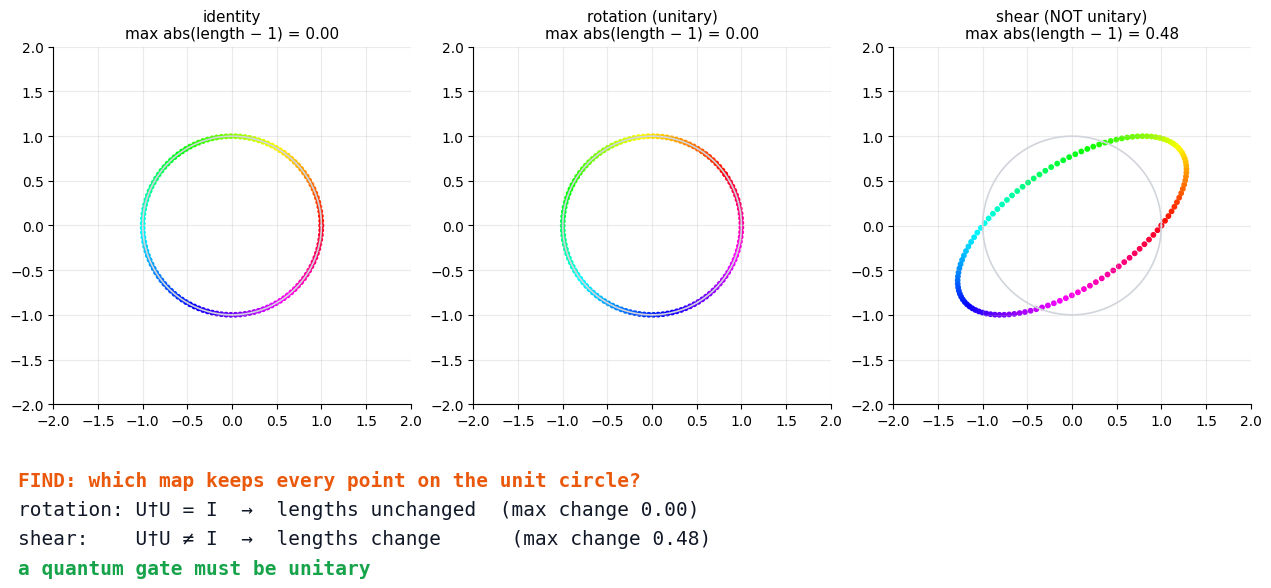

In [28]:
theta = np.deg2rad(35)
R_rot = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])   # unitary (orthogonal)
S_shear = np.array([[1.0, 0.8], [0.0, 1.0]])                                           # shear: not unitary

t = np.linspace(0, 2 * np.pi, 120)
P = np.vstack([np.cos(t), np.sin(t)])

fig, axs = plt.subplots(1, 3, figsize=(12.6, 4.6))
devs = []
for ax, (name, M) in zip(axs, [("identity", np.eye(2)), ("rotation (unitary)", R_rot), ("shear (NOT unitary)", S_shear)]):
    Q = M @ P
    devs.append(np.abs(np.linalg.norm(Q, axis=0) - 1).max())
    ax.plot(np.cos(t), np.sin(t), color="#d1d5db", lw=1.2)
    ax.scatter(Q[0], Q[1], c=t, cmap="hsv", s=10)
    ax.set_aspect("equal")
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.grid(alpha=0.25)
    ax.set_title(f"{name}\nmax abs(length − 1) = {devs[-1]:.2f}", fontsize=11)
show_steps("FIND: which map keeps every point on the unit circle?", [
    f"rotation: U†U = I  →  lengths unchanged  (max change {devs[1]:.2f})",
    f"shear:    U†U ≠ I  →  lengths change      (max change {devs[2]:.2f})",
    "a quantum gate must be unitary"])

plt.show()

#### ML view: orthogonal and unitary maps never explode or vanish

Deep nets and RNNs suffer from exploding or vanishing signals because repeated multiplication by `W` scales the norm like `‖W‖ᵏ`. **Orthogonal initialization** and **unitary RNNs** fix this by using norm-preserving maps: exactly the property quantum circuits have for free. Stacking 50 gates keeps the state valid.

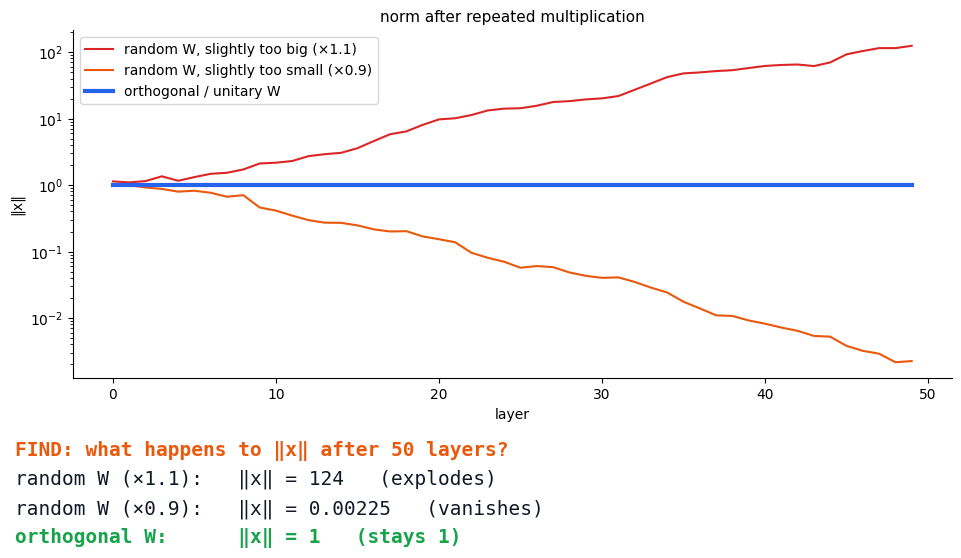

In [29]:
rng = np.random.default_rng(9)
n, depth = 64, 50
x0 = rng.normal(size=n)
x0 = x0 / np.linalg.norm(x0)


def run(make_W):
    """Norm of the signal after each of `depth` repeated multiplications."""
    x, norms = x0.copy(), []
    for _ in range(depth):
        x = make_W() @ x
        norms.append(np.linalg.norm(x))
    return norms


gauss = lambda s: (lambda: s * rng.normal(size=(n, n)) / np.sqrt(n))
Qmat, _ = np.linalg.qr(rng.normal(size=(n, n)))                    # one fixed orthogonal matrix
big, small, orth = run(gauss(1.1)), run(gauss(0.9)), run(lambda: Qmat)

plt.figure(figsize=(7.4, 4.2))
plt.semilogy(big, color=RED, label="random W, slightly too big (×1.1)")
plt.semilogy(small, color=ORANGE, label="random W, slightly too small (×0.9)")
plt.semilogy(orth, color=BLUE, lw=3, label="orthogonal / unitary W")
plt.xlabel("layer")
plt.ylabel("‖x‖")
plt.legend(loc="upper left")
plt.title("norm after repeated multiplication", fontsize=11)
show_steps("FIND: what happens to ‖x‖ after 50 layers?", [
    f"random W (×1.1):   ‖x‖ = {big[-1]:.3g}   (explodes)",
    f"random W (×0.9):   ‖x‖ = {small[-1]:.3g}   (vanishes)",
    f"orthogonal W:      ‖x‖ = {orth[-1]:.3g}   (stays 1)"])

plt.show()

**R — Result.** `X`, `Z` and `H` are all unitary **and** Hermitian; the shear is neither. A rotation keeps every point on the circle, a shear does not, so a shear can never be a gate.

<span style="color:#dc2626">**Unitary = norm-preserving = valid gate.**</span> The same property keeps deep networks stable: 50 orthogonal layers leave `‖x‖` at 1, while a 10% error in the scale makes the signal explode or vanish.

### 2.16 Preview: tensor product

> A first look. The notebooks on multi-qubit systems develop this in depth.

**S — Situation.** One qubit is a vector in `ℂ²`. To describe **two or more qubits** you must combine their spaces. In ML the same operation is **feature crossing**.

**T — Task.** Combine two vectors into one, and tell products apart from entangled states.

**A — Action.** The **tensor (Kronecker) product** of two vectors lists all pairwise products. The spaces combine as `ℂᵐ ⊗ ℂⁿ = ℂ^(mn)`:

$$\begin{pmatrix}a\\b\end{pmatrix}\otimes\begin{pmatrix}c\\d\end{pmatrix}=\begin{pmatrix}ac\\ad\\bc\\bd\end{pmatrix}$$

- <span style="color:#dc2626">Dimensions **multiply**</span> — hence `2ⁿ` for `n` qubits
- gates on separate qubits combine as `A ⊗ B`
- not every vector in `ℂ⁴` is a product `u ⊗ v`. The rest are **entangled**.
- reshape the 4-vector into a `2×2` matrix `M`: a product state is exactly a **rank-1** matrix (`M = u vᵀ`)

In Python: **`np.kron(u, v)`** and `state.reshape(2, 2)`, `np.linalg.matrix_rank(...)`.

<div style="border-left: 5px solid #ea580c; background: rgba(234, 88, 12, 0.10); padding: 8px 16px; border-radius: 4px;">

<b style="color:#ea580c">🟠 EXAMPLE</b>: take the product state `u ⊗ v` with `u = (1, 2i)/√5` and `v = (3, 4)/5`, and the Bell state `(|00⟩ + |11⟩)/√2`. Which one can be factored?

</div>

In [30]:
u = np.array([1, 2j]) / np.sqrt(5)
v = np.array([3, 4]) / 5
prod = np.kron(u, v)                                   # product state in C^4
bell = np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2)

print("kron(u, v) =", prod)
print("rank of reshape(product) =", np.linalg.matrix_rank(prod.reshape(2, 2)))
print("rank of reshape(bell)    =", np.linalg.matrix_rank(bell.reshape(2, 2)))

kron(u, v) = [0.268+0.j    0.358+0.j    0.   +0.537j 0.   +0.716j]
rank of reshape(product) = 1
rank of reshape(bell)    = 2


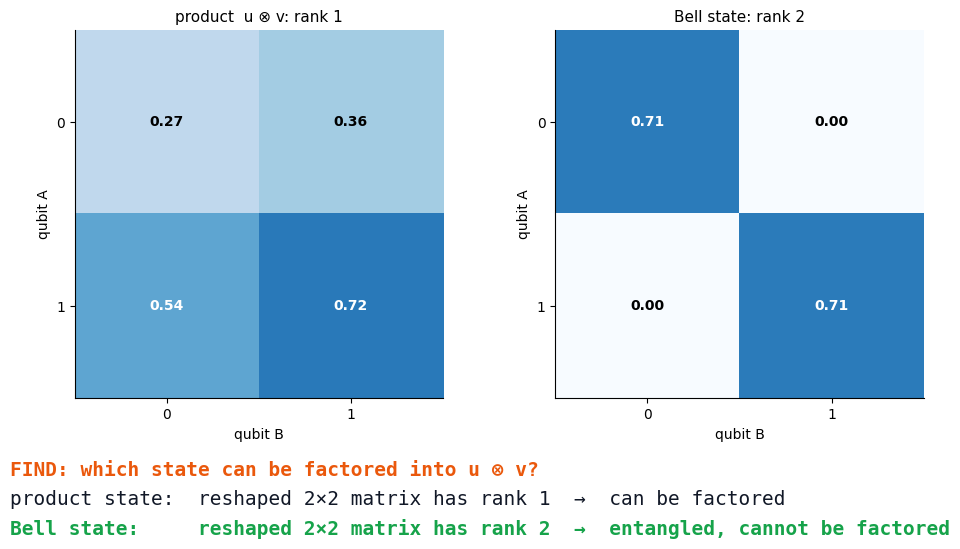

In [31]:
fig, axs = plt.subplots(1, 2, figsize=(9.6, 4.4))
ranks = []
for ax, (name, s) in zip(axs, [("product  u ⊗ v", prod), ("Bell state", bell)]):
    M = abs(s.reshape(2, 2))
    sv = np.linalg.svd(s.reshape(2, 2), compute_uv=False)
    ranks.append(int(np.sum(sv > 1e-9)))
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    for (i, j), val in np.ndenumerate(M):
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="white" if val > 0.5 else "black", fontweight="bold")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xlabel("qubit B")
    ax.set_ylabel("qubit A")
    ax.set_title(f"{name}: rank {ranks[-1]}", fontsize=11)
show_steps("FIND: which state can be factored into u ⊗ v?", [
    f"product state:  reshaped 2×2 matrix has rank {ranks[0]}  →  can be factored",
    f"Bell state:     reshaped 2×2 matrix has rank {ranks[1]}  →  entangled, cannot be factored"])

plt.show()

#### ML view: feature crossing and low-rank structure

- `np.kron(u, v)` is the **outer-product / feature-crossing** layer: all pairwise products `uᵢvⱼ` (as in bilinear pooling or factorization machines).
- A product state is a **rank-1 tensor**; an entangled state is a higher-rank one. Quantum "expressivity" partly means access to correlations that low-rank (product) models miss: the same trade-off as rank in matrix and tensor factorization.

In [32]:
rng = np.random.default_rng(10)
# a "user" embedding x "item" embedding, crossed: rank 1 by construction
user, item = rng.normal(size=3), rng.normal(size=4)
crossed = np.kron(user, item).reshape(3, 4)
print("crossed shape:", crossed.shape, "  rank:", np.linalg.matrix_rank(crossed))

# a generic interaction matrix is NOT rank 1: it needs a sum of crosses (= "entangled")
generic = rng.normal(size=(3, 4))
print("generic rank :", np.linalg.matrix_rank(generic))

crossed shape: (3, 4)   rank: 1
generic rank : 3


**R — Result.** The product state reshapes to a rank-1 matrix (a clean outer product); the Bell state is diagonal with equal entries, rank 2, and cannot be factored. Dimensions multiply, so `n` qubits need `2ⁿ` amplitudes.

<span style="color:#dc2626">**Entanglement = not a product = rank above 1.**</span> In ML terms: a crossed feature is rank 1, a generic interaction matrix is not.

### 2.17 Summary — complex vectors

**One sentence.** A complex vector is a list of `n` complex numbers (`n` arrows, one per complex plane). With three operations, add, scale and the **inner product**, it carries everything a qubit state needs: sizes (probabilities), phases (interference) and a length that must be 1.

**Every point on one page**

| Point | What it is | Python | Picture | Why it matters for qubits | ML analogue |
|---|---|---|---|---|---|
| Complex vector | list of `n` complex numbers | `np.array([...], dtype=complex)` | `n` arrows, one per plane | a state `(α, β)` | embedding, FFT output |
| Add, subtract | component by component | `u + w`, `u - w` | tip to tail in each plane | amplitudes add → interference | adding embeddings |
| Scale | every component times `c` | `c * v` | all arrows turn and stretch together | a gate multiplies amplitudes | scaling a feature vector |
| Global / relative phase | turn all arrows / turn one | `np.exp(1j * g) * v` | angle between the arrows | global: invisible, relative: visible | a delay in the FFT |
| Conjugate | flip the sign of every imaginary part | `v.conj()` | mirror across the real axis | the bra (the conjugate row `v†`) | complex-valued features |
| Inner product | `Σ conj(uₖ)·vₖ` | `np.vdot(u, v)` | products tip to tail | overlap of two states | dot product |
| Norm | length from the component lengths | `np.linalg.norm(v)` | hypotenuse | must be 1 for a state | L2 norm |
| Normalization | divide by the length | `v / np.linalg.norm(v)` | land on the unit circle | squared amplitudes = probabilities (Born rule) | L2-normalized embedding |
| Angle, overlap | `cos θ = abs(⟨u, v⟩)/(‖u‖‖v‖)` | `abs(np.vdot(u, v))**2` | angle between two states | probability of finding one in the other | cosine similarity |
| *Preview:* space, basis | all vectors of one size; coordinates `c = B†ψ` | `B.conj().T @ psi` | same arrow, new axes | state space `ℂ^(2ⁿ)`; Z vs X basis | feature space; PCA scores |
| *Preview:* matrices | a linear map; unitary keeps length | `A @ psi` | the grid moves | gates | dense layer; orthogonal init |
| *Preview:* eigen | directions a matrix only stretches | `np.linalg.eigh(A)` | stretched axes | measurement outcomes | PCA |
| *Preview:* tensor product | combine systems | `np.kron(u, v)` | rank of a 2×2 matrix | multi-qubit states, entanglement | feature crossing |

**Six ideas to remember**
1. **A complex vector is a list of arrows.** Each component has a length ("how much") and a phase ("which way"). A real vector is the case where every imaginary part is 0.
2. **Add and scale work on every component alike.** A complex scalar turns and stretches all arrows together; adding adds amplitudes, not probabilities.
3. **Only the relative phase is physical.** A global phase is a free change of viewpoint; a relative phase decides interference.
4. **The conjugate makes lengths real.** `conj(vₖ)·vₖ = |vₖ|²`, so `⟨v|v⟩` is real and never negative.
5. **The inner product is the overlap.** `|⟨u|v⟩|²` is the probability of finding `u` in `v`; orthogonal means 0.
6. **Unit length turns squared amplitudes into probabilities.** Normalizing is how a vector becomes a state (the Born rule).

**Three slogans**
- **Conjugate, multiply, add: that is the inner product.**
- **Global phase: invisible. Relative phase: visible.**
- **A state is a unit vector.**

**Common mistakes**
- Using `u @ v` or `np.dot` for complex vectors: they do not conjugate. Use `np.vdot(u, v)`.
- Reading `|vₖ|²` as a probability before normalizing: the squared lengths must add up to 1 first.
- Treating `(1, i)/√2` and `i·(1, i)/√2` as different states: they differ by a global phase only.
- Adding probabilities when you should add amplitudes (or the other way round).
- Forgetting that Python counts components from 0: `v[0]` is the first one.

**Worked example — from a raw vector to a deterministic outcome.** Take the raw vector `v = (1 + i, 1 − i)` and follow the points above:

1. **Norm:** `|v₀|² = |v₁|² = 2`, so `‖v‖ = 2`.
2. **Normalize:** `v̂ = ((1 + i)/2, (1 − i)/2)`, probabilities `(0.5, 0.5)`.
3. **Inner product with itself:** `⟨v̂|v̂⟩ = 1`: a valid state.
4. **Global phase** `e^{0.7i}`: probabilities and overlap with `|0⟩` do not change.
5. **Mix** with `H`: `(0.5, 0.5)` again, a fair coin.
6. **Relative phase** of 90° on the second component, then mix: `(1, 0)`. The two amplitudes now add in the first output and cancel in the second.

Same lengths before and after the relative phase, a completely different result: the information was in the phase.

In [33]:
v = np.array([1 + 1j, 1 - 1j])                              # a raw vector

print("1) norm            :", norm(v), "   squared lengths", abs(v) ** 2)
vhat = normalize(v)
print("2) normalized      :", vhat, "   probabilities", abs(vhat) ** 2)
print("3) <vhat|vhat>     :", clean(np.vdot(vhat, vhat)), "   (a valid state)")

glob = np.exp(0.7j) * vhat
print("4) global phase    : probabilities", abs(glob) ** 2, "  overlap with |0>", round(abs(np.vdot(ket0, glob)) ** 2, 3), "(unchanged)")
print("5) mix with H      : probabilities", abs(Hg @ vhat) ** 2, "  (a fair coin)")
rel = vhat * np.array([1, 1j])                              # relative phase of 90 degrees on component 1
print("6) relative phase, then mix: probabilities", clean(abs(Hg @ rel) ** 2), "  (deterministic)")

1) norm            : 2.0    squared lengths [2. 2.]
2) normalized      : [0.5+0.5j 0.5-0.5j]    probabilities [0.5 0.5]
3) <vhat|vhat>     : (1+0j)    (a valid state)
4) global phase    : probabilities [0.5 0.5]   overlap with |0> 0.5 (unchanged)
5) mix with H      : probabilities [0.5 0.5]   (a fair coin)
6) relative phase, then mix: probabilities [1. 0.]   (deterministic)


### 2.18 The big picture: four takeaways

**One line for programmers:** a complex vector is a `float` array of length `2n` that knows which pairs of numbers are arrows.

**1. A complex vector is a list of arrows: a size and a direction for every component.**
A real vector answers "how much of each feature?". A complex vector answers "how much **and** which way, for each component?" A qubit is exactly two such arrows.
*Benefit:* the same object carries probabilities (the lengths) and the interference information (the phases).

**2. Only the relative phase between the arrows is physical.**
Turn all arrows together and nothing observable changes (a global phase); turn one arrow and the outcome of a later mixing changes.
*Benefit:* you know which parts of a state vector you may freely rescale and which you must keep.

**3. The inner product, with its conjugate, turns two vectors into an overlap.**
`⟨u|v⟩ = Σ conj(uₖ)·vₖ` is one complex number; its size squared is the probability of finding `u` in `v`; with `u = v` it is the squared length.
*Benefit:* similarity, length, orthogonality and probability all come from one operation.

**4. Unit length makes squared lengths probabilities.**
Divide by the norm and `Σ |vₖ|² = 1`: the squared lengths are a probability distribution (the Born rule). Normalized states of one qubit fill a sphere.
*Benefit:* normalization is the single step that connects a vector to something you can measure.

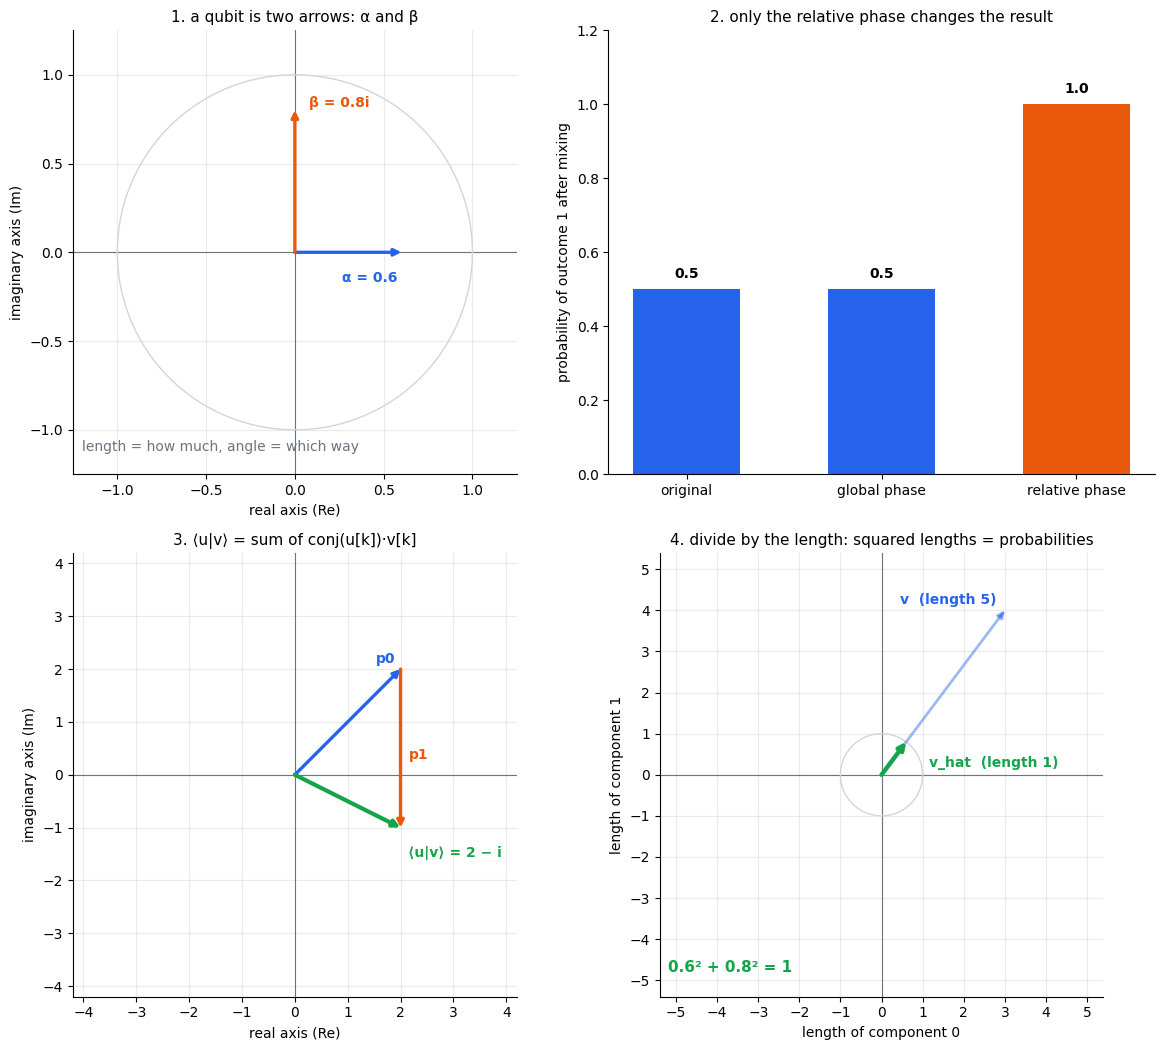

In [34]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10.6))

# ---- 1. a qubit = two arrows --------------------------------------------------------------
ax = new_plane(lim=1.25, title="1. a qubit is two arrows: α and β", ax=axs[0, 0], unit_circle=True)
alpha, beta = 0.6, 0.8j
draw_arrow(ax, alpha, BLUE, "α = 0.6", offset=(-0.02, -0.17), ha="right")
draw_arrow(ax, beta, ORANGE, "β = 0.8i", offset=(0.08, 0.02))
ax.text(-1.2, -1.12, "length = how much, angle = which way", color=GRAY)

# ---- 2. global phase invisible, relative phase visible ------------------------------------
ax = axs[0, 1]
psi = np.array([1, 1j]) / np.sqrt(2)
cases = {"original": psi, "global phase": np.exp(1j * np.pi / 2) * psi, "relative phase": psi * np.array([1, 1j])}
after = [abs(Hg @ s) ** 2 for s in cases.values()]
bars = ax.bar(list(cases), [p[1] for p in after], color=[BLUE, BLUE, ORANGE], width=0.55)
for rect, p in zip(bars, after):
    ax.text(rect.get_x() + rect.get_width() / 2, p[1] + 0.03, f"{p[1]:.1f}", ha="center", fontweight="bold")
ax.set_ylim(0, 1.2)
ax.set_ylabel("probability of outcome 1 after mixing")
ax.set_title("2. only the relative phase changes the result", fontsize=11)

# ---- 3. inner product = products tip to tail ----------------------------------------------
u, w = np.array([2, 1j]), np.array([1 + 1j, 3])
p = u.conj() * w
ax = new_plane(lim=4.2, title="3. ⟨u|v⟩ = sum of conj(u[k])·v[k]", ax=axs[1, 0], step=1)
draw_arrow(ax, p[0], BLUE, "p0", offset=(-0.1, 0.12), ha="right")
draw_arrow(ax, p[0] + p[1], ORANGE, "p1", tail=p[0], offset=(0.15, 1.3))
draw_arrow(ax, np.vdot(u, w), GREEN, f"⟨u|v⟩ = {cshort(np.vdot(u, w))}", lw=3, offset=(0.15, -0.55))

# ---- 4. normalization -> probabilities ----------------------------------------------------
ax = new_plane(lim=5.4, title="4. divide by the length: squared lengths = probabilities", ax=axs[1, 1], unit_circle=True, step=1)
ax.set_xlabel("length of component 0")
ax.set_ylabel("length of component 1")
draw_arrow(ax, 3 + 4j, BLUE, "v  (length 5)", alpha=0.45, lw=2, offset=(-0.2, 0.15), ha="right")
draw_arrow(ax, 0.6 + 0.8j, GREEN, "v_hat  (length 1)", lw=3.2, offset=(0.55, -0.6))
ax.text(-5.2, -4.8, "0.6² + 0.8² = 1", color=GREEN, fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()

---
## Exercises

Do them on paper first, then verify in code. Exercises 1 and 8 review notebook 1; the others use the points of this notebook and its previews.

**Exercise 1 — complex arithmetic.** Compute $(1+2i)(3-i)$ and $|1+2i|$ by hand, then check with Python complex numbers. What does multiplying by $i$ do geometrically?

In [35]:
# TODO

**Exercise 2 — inner product.** For $u=(1, i)/\sqrt2$ and $v=(1, 1)/\sqrt2$ compute $\langle u|v\rangle$, $\langle v|u\rangle$, and $|\langle u|v\rangle|^2$. How are the first two related?

In [36]:
# TODO

**Exercise 3 — orthonormal basis.** Show that $\{(1,i)/\sqrt2,\ (1,-i)/\sqrt2\}$ is an orthonormal basis of $\mathbb{C}^2$. Expand $|0\rangle$ in it and check $\sum|c_i|^2=1$.

In [37]:
# TODO

**Exercise 4 — unitarity.** Write `is_unitary` for the matrix $\begin{pmatrix}1&0\\0&i\end{pmatrix}$ and for $\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ (without the $1/\sqrt2$). Which are unitary? Fix the second.

In [38]:
# TODO

**Exercise 5 — expectation.** For $|\psi\rangle=(\cos\tfrac{\theta}{2},\sin\tfrac{\theta}{2})$ show $\langle Z\rangle=\cos\theta$ and plot it for $\theta\in[0,2\pi]$. Why is this the shape of a QML model's output as a function of a rotation angle?

In [39]:
# TODO

**Exercise 6 — tensor product.** Build $|+\rangle\otimes|-\rangle$, list its 4 amplitudes, and verify it has rank 1. Then check that $\tfrac{1}{\sqrt2}(|01\rangle+|10\rangle)$ has rank 2.

In [40]:
# TODO

**Exercise 7 (ML link).** Write a kernel $k(x,y)=|\langle\phi(x)|\phi(y)\rangle|^2$ with $\phi(x)=(\cos x,\sin x)$ and fit scikit-learn's `SVC(kernel='precomputed')` on `make_moons` after scaling features to $[0,\pi]$ (use only the first feature). Report accuracy vs. an RBF kernel.

In [41]:
# TODO

**Exercise 8 — Euler.** Show numerically that $e^{i\pi}+1=0$. Then use $e^{i\alpha}e^{i\beta}=e^{i(\alpha+\beta)}$ and Euler's formula to derive $\cos(\alpha+\beta)=\cos\alpha\cos\beta-\sin\alpha\sin\beta$ (compare real parts), and verify it for two angles.

In [42]:
# TODO

**Exercise 9 — normalization.** Normalize $(1+i,\ 2,\ -i)$ and report the three outcome probabilities. Multiply the state by $e^{0.7i}$ and show the probabilities do not change. Multiply only the *second* component by $e^{0.7i}$ — do the probabilities change? Does the state?

In [43]:
# TODO

**Exercise 10 — angles.** Compute the Hilbert-space angle and the Bloch-sphere angle between $|0\rangle$ and $\cos\tfrac{\pi}{8}|0\rangle+\sin\tfrac{\pi}{8}|1\rangle$. What is the relation between the two?

In [44]:
# TODO

**Exercise 11 — change of basis.** Write $|\psi\rangle=(3/5,\ 4i/5)$ in the Hadamard basis with $c=B^\dagger\psi$. Check $\sum\lvert c_i\rvert^2=1$ and that $c=H\psi$. Then give the coordinates in the basis $\{(1,i)/\sqrt2,\ (1,-i)/\sqrt2\}$.

In [45]:
# TODO

**Exercise 12 — linear maps.** A linear map sends $|0\rangle\to|+\rangle$ and $|1\rangle\to|-\rangle$. Write its matrix from the *columns = images* rule. Which gate is it? What does it do to $|+\rangle$?

In [46]:
# TODO

**Exercise 13 — eigenvalues.** Find the eigenvalues and eigenvectors of $Y=\begin{bmatrix}0&-i\\i&0\end{bmatrix}$ by hand ($\det(Y-\lambda I)=0$) and check with `np.linalg.eigh`. If $Y$ is measured on $|0\rangle$, what are the outcomes, their probabilities, and $\langle Y\rangle$?

In [47]:
# TODO

**Exercise 14 — eigen and gates.** Show that the eigenvalues of $R_Z(\theta)$ are $e^{\mp i\theta/2}$, and that $|0\rangle$ and $|1\rangle$ stay eigenvectors for any $\theta$. Why does $R_Z$ never change computational-basis probabilities?

In [48]:
# TODO

**Video to revisit:** [Vectors, chapter 1 of "Essence of linear algebra" (3Blue1Brown, YouTube)](https://www.youtube.com/watch?v=fNk_zzaMoSs)

**Next:** `3_complex_vectors_space.ipynb` (linear combinations, basis, dimension, linear independence), then `4_inner_product_space.ipynb` and `5_Hilbert_space.ipynb`, then the qubits notebook (`2_qubits_and_measurement.ipynb`: state vectors and measurement).